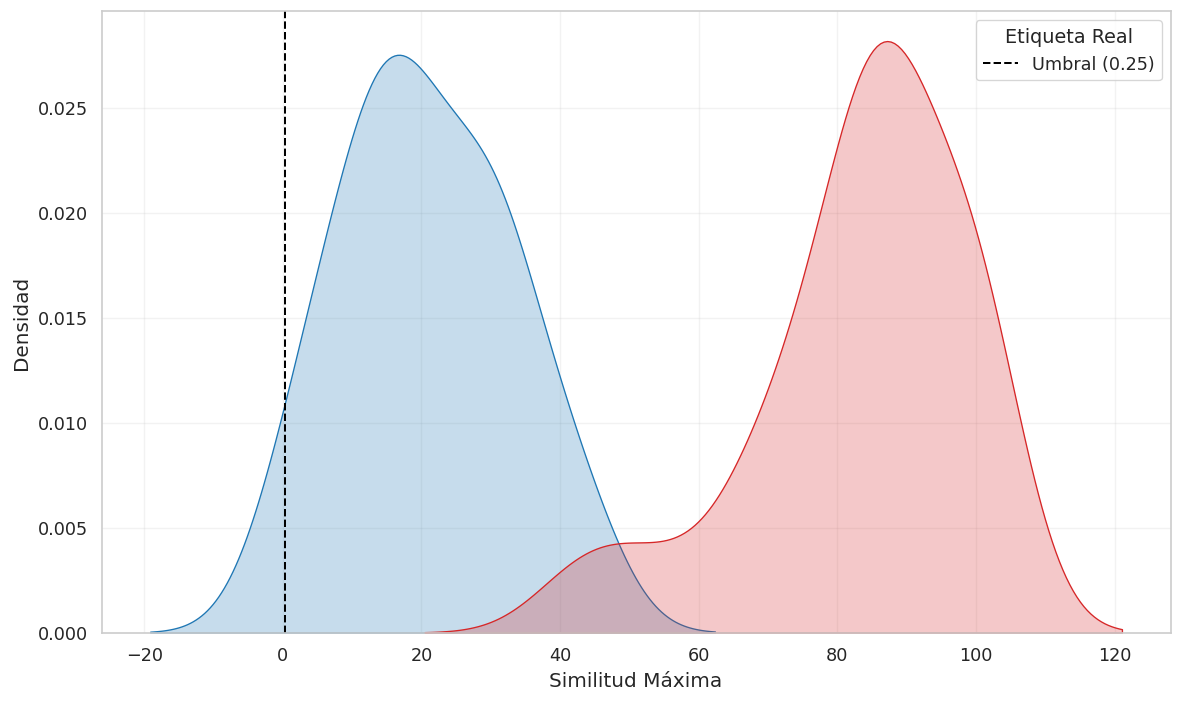

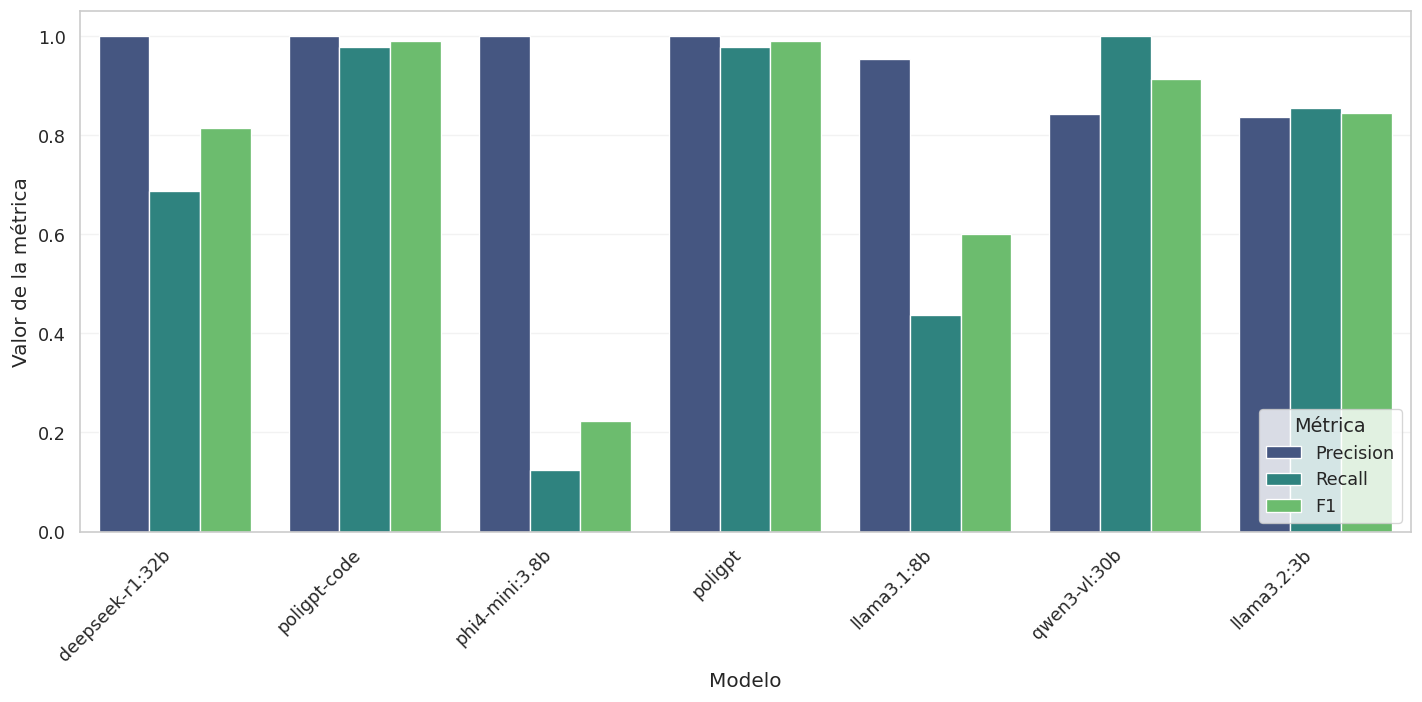

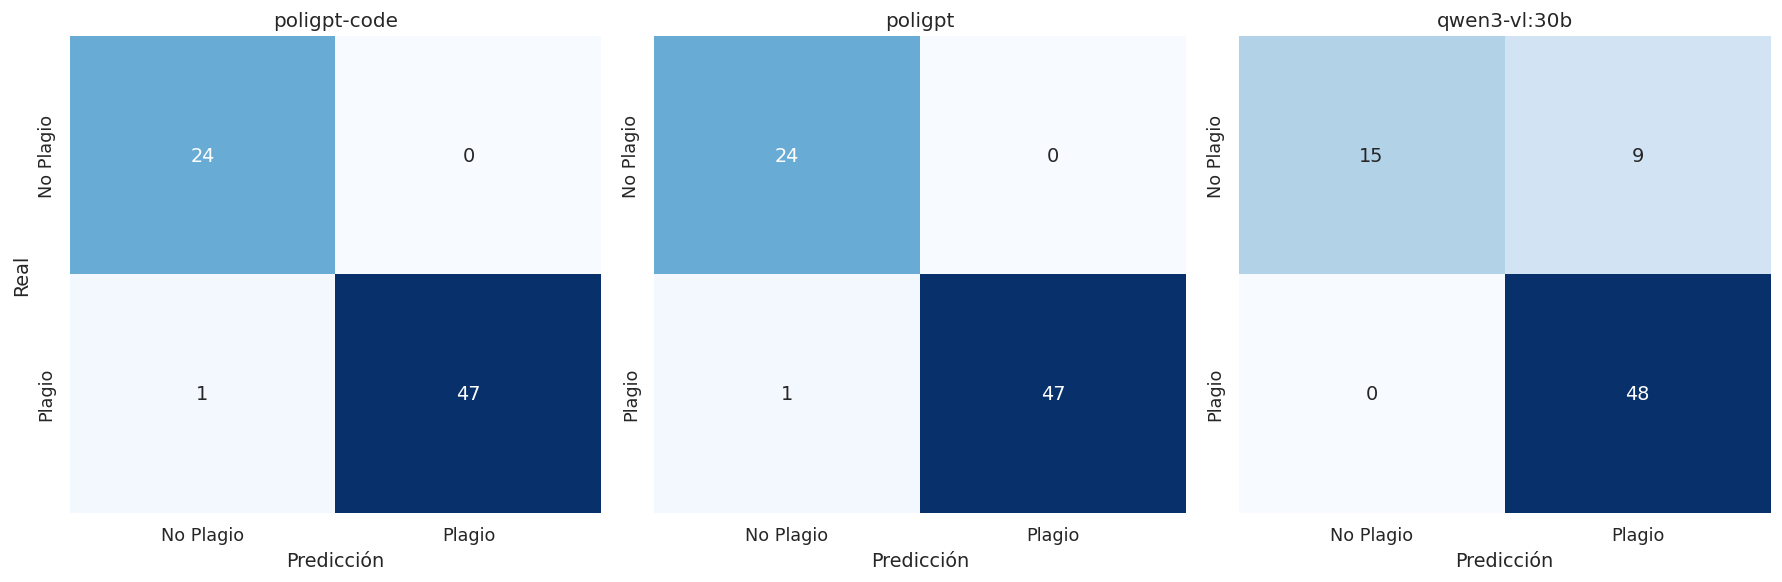

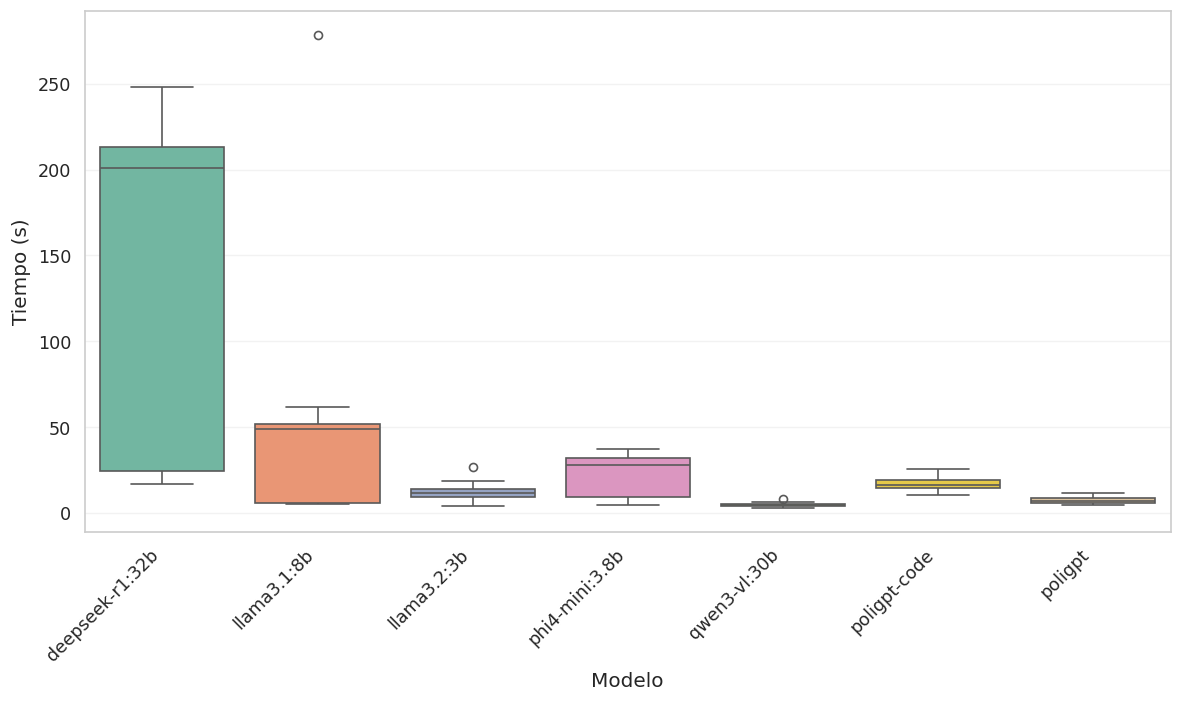

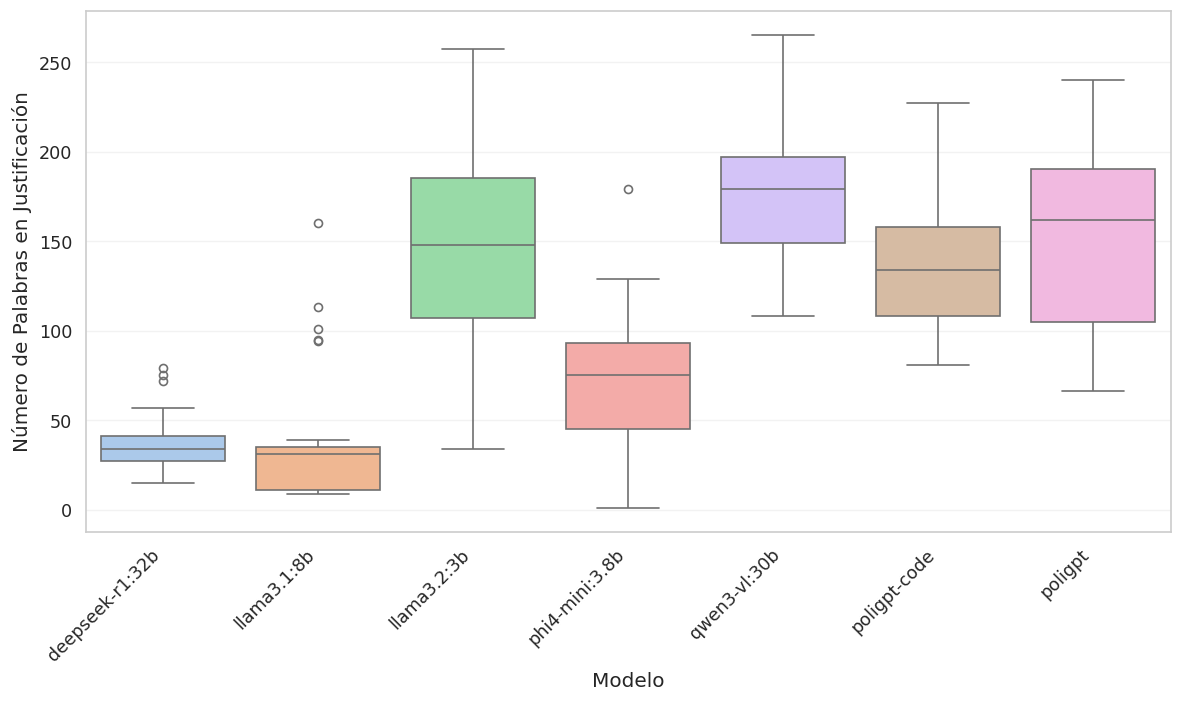

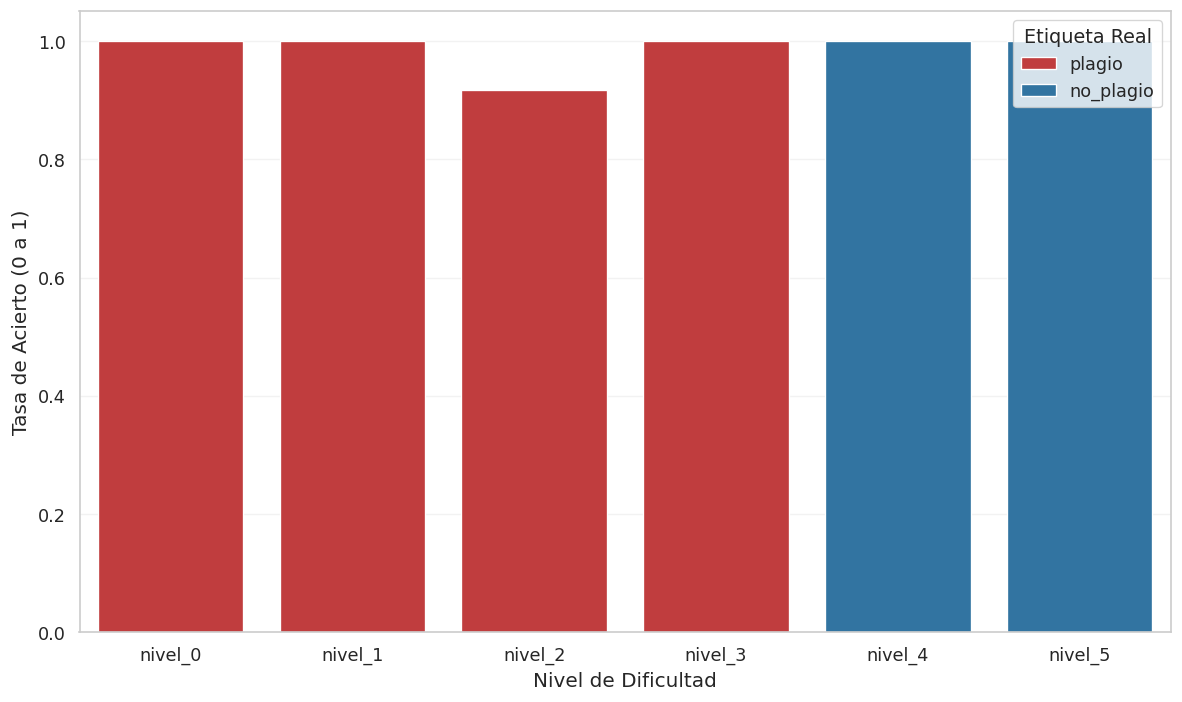

In [79]:
# Importación de librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Configuración "modo TFG" para visualizar correctamente en Jupyter
# (Si usas Jupyter clásico, descomenta la siguiente línea; en JupyterLab o VSCode suele venir por defecto)
# %matplotlib inline 

sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=1.2) 

# Carga de datos
df = pd.read_csv('resultados_comparativa_llm.csv')

# =========================================================
# 1. Gráfico 1: Distribución
# =========================================================
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='sim_maxima', hue='etiqueta_real', fill=True, common_norm=False, palette={'plagio':'#d62728', 'no_plagio':'#1f77b4'})
plt.axvline(0.25, color='black', linestyle='--', label='Umbral (0.25)')
plt.xlabel('Similitud Máxima', fontsize=12)
plt.ylabel('Densidad', fontsize=12)
plt.legend(title='Etiqueta Real')
plt.tight_layout()
plt.show()

# -- Preparación de datos para los LLMs (Fase 2) --
modelos = ['deepseek-r1:32b', 'llama3.1:8b', 'llama3.2:3b', 'phi4-mini:3.8b', 'qwen3-vl:30b', 'poligpt-code', 'poligpt']
y_true = (df['etiqueta_real'] == 'plagio').astype(int)

metricas = []
for m in modelos:
    y_pred = (df[f'prediccion_{m}'] == 'plagio').astype(int)
    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    metricas.append({'Modelo': m, 'Precision': p, 'Recall': r, 'F1': f1})

df_metrics = pd.DataFrame(metricas).sort_values(by='Precision', ascending=False)
top_3_modelos = df_metrics.sort_values(by='F1', ascending=False)['Modelo'].head(3).tolist()

# =========================================================
# 2. Gráfico 2: Métricas End-to-End
# =========================================================
df_metrics_melt = df_metrics.melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')
plt.figure(figsize=(12, 6))
sns.barplot(data=df_metrics_melt, x='Modelo', y='Valor', hue='Métrica', palette='viridis')
plt.ylim(0, 1.05)
plt.xlabel('Modelo', fontsize=12)
plt.ylabel('Valor de la métrica', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(loc='lower right', title='Métrica')
plt.tight_layout()
plt.show()

# =========================================================
# 3. Gráfico 3: Matrices de Confusión (Mejores 3 modelos)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, m in enumerate(top_3_modelos):
    y_pred = (df[f'prediccion_{m}'] == 'plagio').astype(int)
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['No Plagio', 'Plagio'], yticklabels=['No Plagio', 'Plagio'])
    axes[i].set_title(m, fontsize=12)
    axes[i].set_xlabel('Predicción')
    axes[i].set_ylabel('Real' if i==0 else '')
plt.tight_layout()
plt.show()

# =========================================================
# 4. Gráfico 4: Coste Temporal
# =========================================================
tiempos_cols = [f'tiempo_{m}' for m in modelos]
df_tiempos = df[tiempos_cols].rename(columns=lambda x: x.replace('tiempo_', ''))
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_tiempos, palette='Set2')
plt.ylabel('Tiempo (s)', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# =========================================================
# 5. Gráfico 5: Justificaciones (Control de Alucinaciones)
# =========================================================
words_df = pd.DataFrame()
for m in modelos:
    col = f'justificacion_{m}'
    counts = df[col].dropna().apply(lambda x: len(str(x).split()))
    temp_df = pd.DataFrame({'Modelo': m, 'Palabras': counts})
    words_df = pd.concat([words_df, temp_df])

plt.figure(figsize=(10, 6))
# Se usa hue y legend=False para evitar el FutureWarning de Seaborn
sns.boxplot(data=words_df, x='Modelo', y='Palabras', hue='Modelo', palette='pastel', legend=False)
plt.ylabel('Número de Palabras en Justificación', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# =========================================================
# 6. Gráfico 6: Acierto por niveles diferenciando clase real
# =========================================================
best_model = top_3_modelos[0]
df['acierto_best'] = (df[f'prediccion_{best_model}'] == df['etiqueta_real'])

plt.figure(figsize=(10, 6))
sns.barplot(data=df, x='nivel', y='acierto_best', hue='etiqueta_real', errorbar=None, palette={'plagio':'#d62728', 'no_plagio':'#1f77b4'})
plt.ylabel('Tasa de Acierto (0 a 1)', fontsize=12)
plt.xlabel('Nivel de Dificultad', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title='Etiqueta Real')
plt.tight_layout()
plt.show()

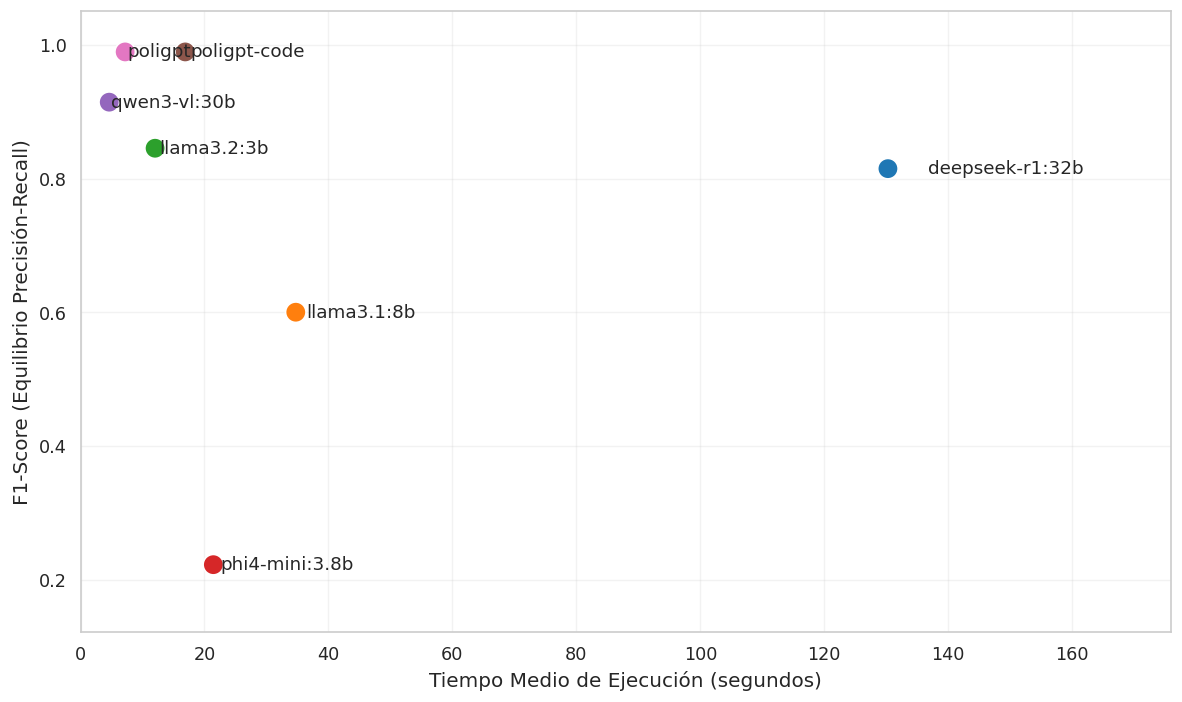

In [80]:
# =========================================================
# 7. Gráfico 7: Trade-off Rendimiento vs Coste Temporal
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, f1_score

# Asegurarnos de que el estilo TFG sigue activo
sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=1.2) 

# Extracción de datos para el scatter plot
tradeoff_data = []
for m in modelos:
    y_pred = (df[f'prediccion_{m}'] == 'plagio').astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    tiempo_medio = df[f'tiempo_{m}'].mean() # Calculamos la media de tiempo de cada modelo
    tradeoff_data.append({
        'Modelo': m, 
        'F1-Score': f1, 
        'Precision': precision, 
        'Tiempo Medio': tiempo_medio
    })

df_tradeoff = pd.DataFrame(tradeoff_data)

plt.figure(figsize=(10, 6))

# Dibujamos los puntos (s=150 es el tamaño del punto)
sns.scatterplot(data=df_tradeoff, x='Tiempo Medio', y='F1-Score', hue='Modelo', 
                s=150, palette='tab10', legend=False)

# Imprimimos el nombre de cada modelo justo al lado de su punto
for i in range(df_tradeoff.shape[0]):
    plt.text(x=df_tradeoff['Tiempo Medio'][i] * 1.05,  # Un 5% de separación para no pisar el punto
             y=df_tradeoff['F1-Score'][i], 
             s=df_tradeoff['Modelo'][i], 
             fontdict=dict(size=11),
             verticalalignment='center')

plt.xlabel('Tiempo Medio de Ejecución (segundos)', fontsize=12)
plt.ylabel('F1-Score (Equilibrio Precisión-Recall)', fontsize=12)

# Ajustamos los límites para que los textos no se salgan del gráfico
plt.xlim(0, df_tradeoff['Tiempo Medio'].max() * 1.35) 
plt.ylim(max(0, df_tradeoff['F1-Score'].min() - 0.1), 1.05)

plt.tight_layout()
plt.show()

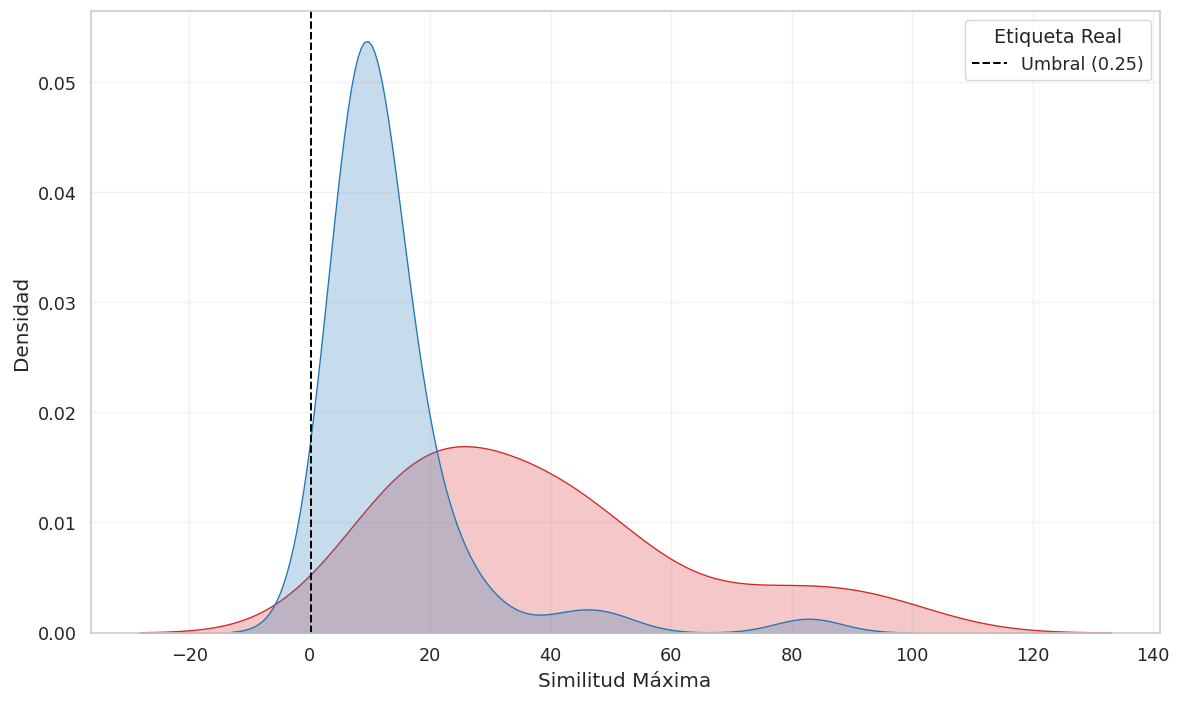

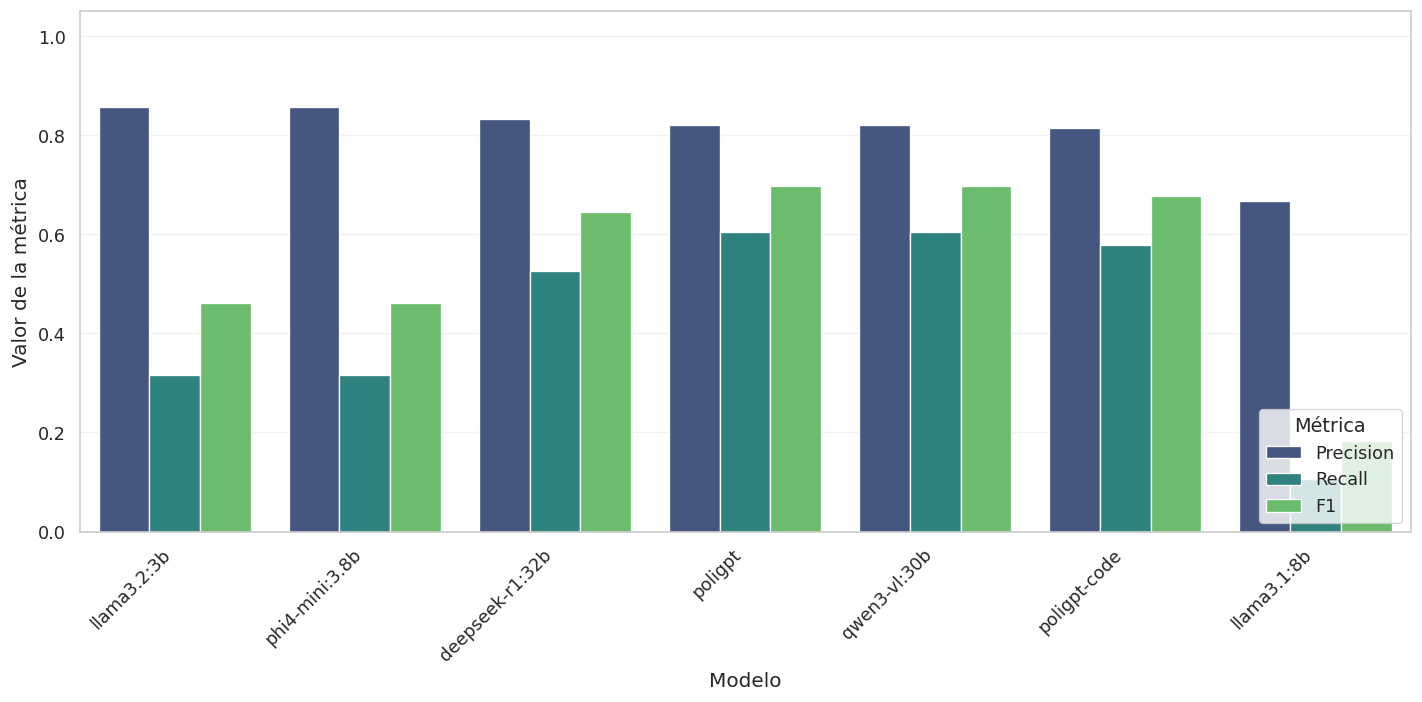

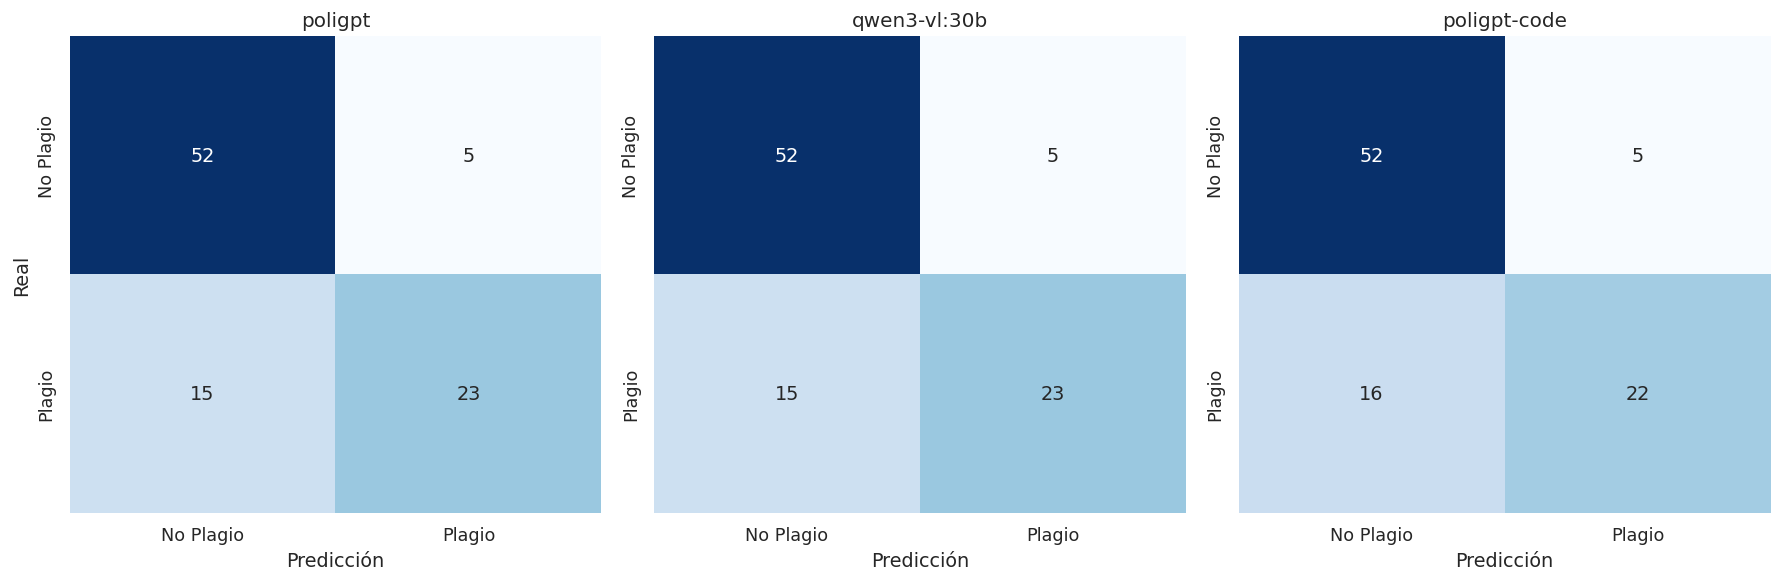

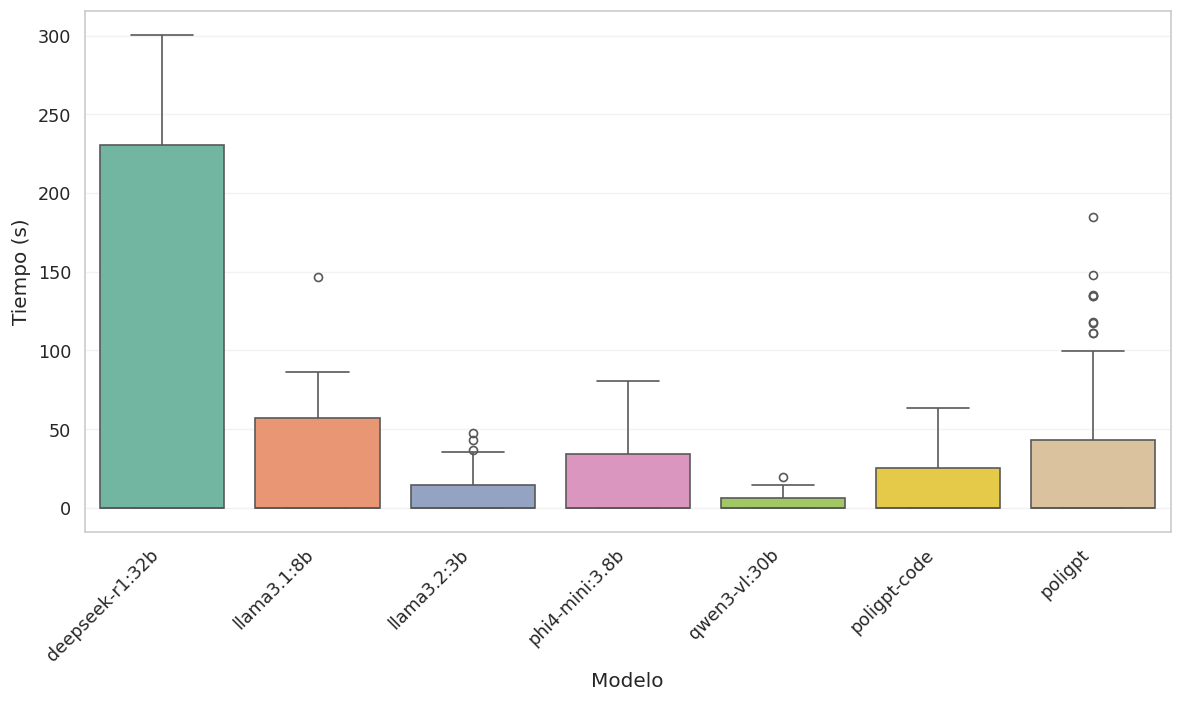

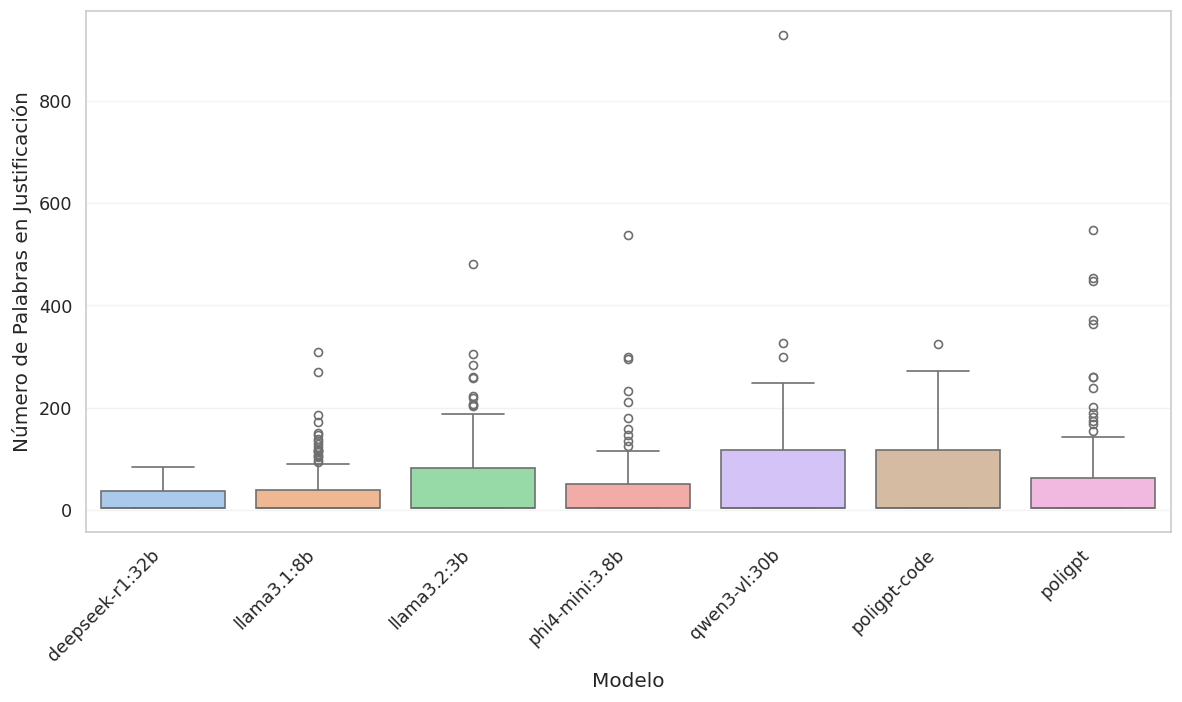

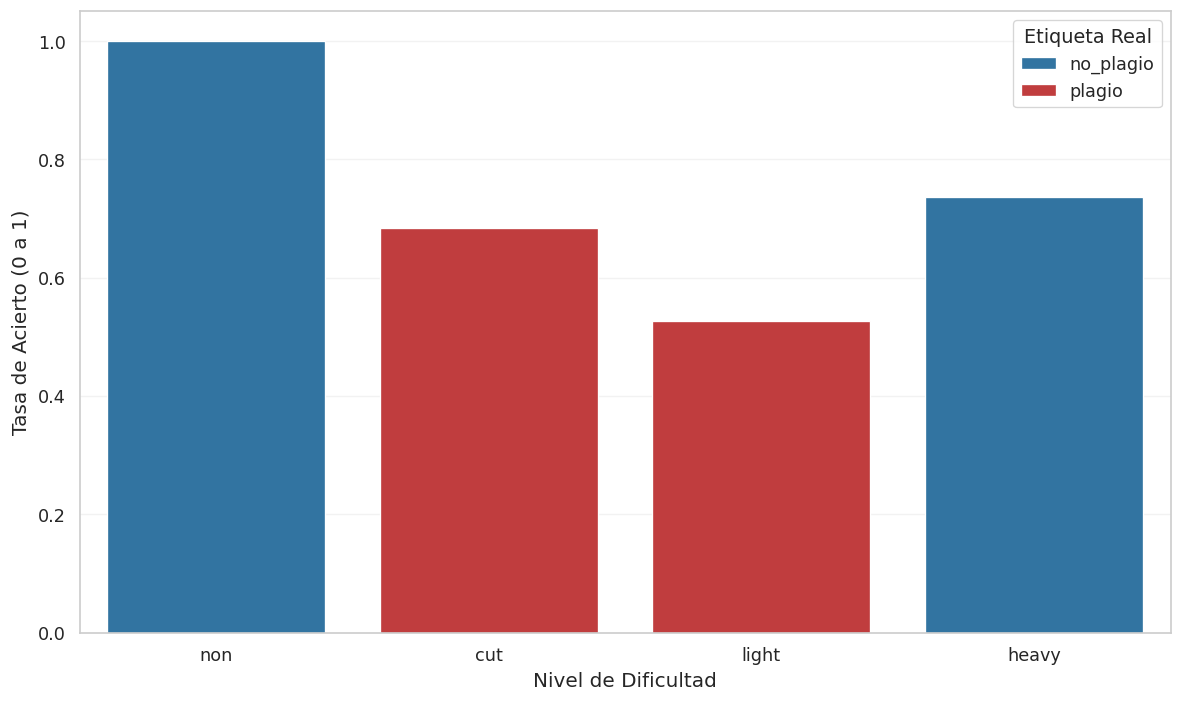

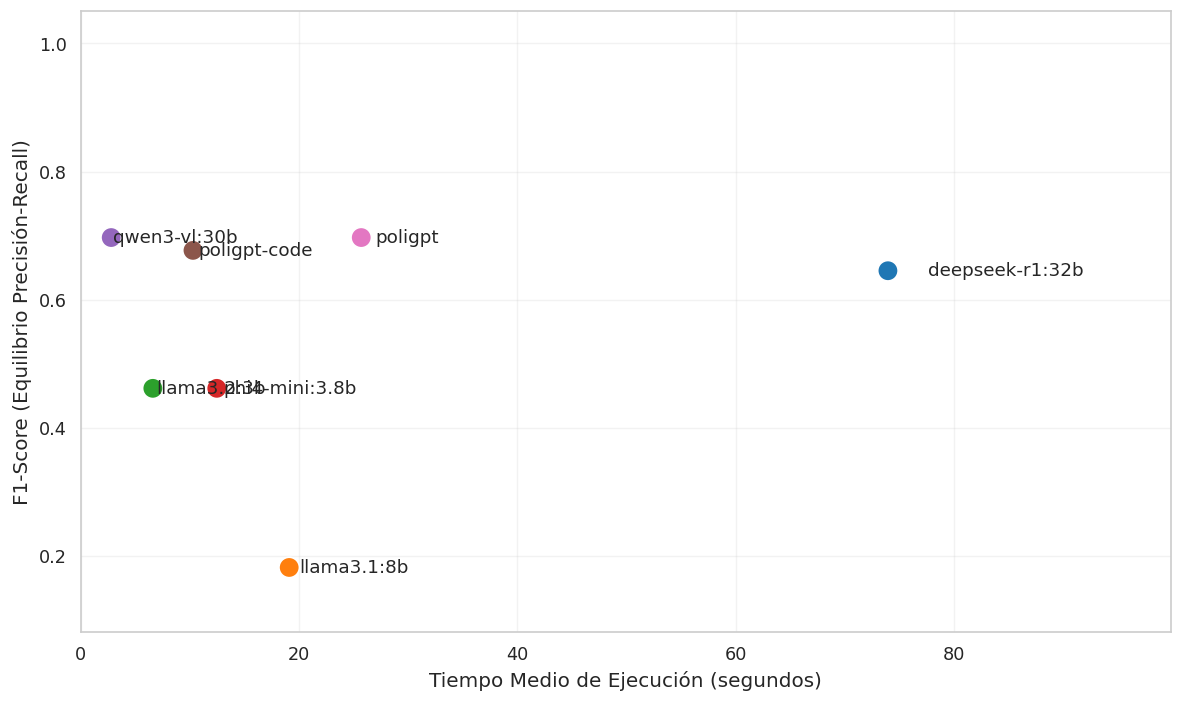

In [81]:
# Importación de librerías
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix

# Configuración "modo TFG" para visualizar correctamente en Jupyter
# (Si usas Jupyter clásico, descomenta la siguiente línea; en JupyterLab o VSCode suele venir por defecto)
# %matplotlib inline 

sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=1.2) 

# Carga de datos
df2 = pd.read_csv('resultados_clough_ancho.csv')

# =========================================================
# 1. Gráfico 1: Distribución
# =========================================================
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df2, x='sim_maxima', hue='etiqueta_real', fill=True, common_norm=False, palette={'plagio':'#d62728', 'no_plagio':'#1f77b4'})
plt.axvline(0.25, color='black', linestyle='--', label='Umbral (0.25)')
plt.xlabel('Similitud Máxima', fontsize=12)
plt.ylabel('Densidad', fontsize=12)
plt.legend(title='Etiqueta Real')
plt.tight_layout()
plt.show()

# -- Preparación de datos para los LLMs (Fase 2) --
modelos = ['deepseek-r1:32b', 'llama3.1:8b', 'llama3.2:3b', 'phi4-mini:3.8b', 'qwen3-vl:30b', 'poligpt-code', 'poligpt']
y_true = (df2['etiqueta_real'] == 'plagio').astype(int)

metricas = []
for m in modelos:
    y_pred = (df2[f'prediccion_{m}'] == 'plagio').astype(int)
    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    metricas.append({'Modelo': m, 'Precision': p, 'Recall': r, 'F1': f1})

df_metrics = pd.DataFrame(metricas).sort_values(by='Precision', ascending=False)
top_3_modelos = df_metrics.sort_values(by='F1', ascending=False)['Modelo'].head(3).tolist()

# =========================================================
# 2. Gráfico 2: Métricas End-to-End
# =========================================================
df_metrics_melt = df_metrics.melt(id_vars='Modelo', var_name='Métrica', value_name='Valor')
plt.figure(figsize=(12, 6))
sns.barplot(data=df_metrics_melt, x='Modelo', y='Valor', hue='Métrica', palette='viridis')
plt.ylim(0, 1.05)
plt.xlabel('Modelo', fontsize=12)
plt.ylabel('Valor de la métrica', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(loc='lower right', title='Métrica')
plt.tight_layout()
plt.show()

# =========================================================
# 3. Gráfico 3: Matrices de Confusión (Mejores 3 modelos)
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, m in enumerate(top_3_modelos):
    y_pred = (df2[f'prediccion_{m}'] == 'plagio').astype(int)
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False,
                xticklabels=['No Plagio', 'Plagio'], yticklabels=['No Plagio', 'Plagio'])
    axes[i].set_title(m, fontsize=12)
    axes[i].set_xlabel('Predicción')
    axes[i].set_ylabel('Real' if i==0 else '')
plt.tight_layout()
plt.show()

# =========================================================
# 4. Gráfico 4: Coste Temporal
# =========================================================
tiempos_cols = [f'tiempo_{m}' for m in modelos]
df_tiempos = df2[tiempos_cols].rename(columns=lambda x: x.replace('tiempo_', ''))
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_tiempos, palette='Set2')
plt.ylabel('Tiempo (s)', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# =========================================================
# 5. Gráfico 5: Justificaciones (Control de Alucinaciones)
# =========================================================
words_df = pd.DataFrame()
for m in modelos:
    col = f'justificacion_{m}'
    counts = df2[col].dropna().apply(lambda x: len(str(x).split()))
    temp_df = pd.DataFrame({'Modelo': m, 'Palabras': counts})
    words_df = pd.concat([words_df, temp_df])

plt.figure(figsize=(10, 6))
# Se usa hue y legend=False para evitar el FutureWarning de Seaborn
sns.boxplot(data=words_df, x='Modelo', y='Palabras', hue='Modelo', palette='pastel', legend=False)
plt.ylabel('Número de Palabras en Justificación', fontsize=12)
plt.xlabel('Modelo', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# =========================================================
# 6. Gráfico 6: Acierto por niveles diferenciando clase real
# =========================================================
best_model = top_3_modelos[0]
df2['acierto_best'] = (df2[f'prediccion_{best_model}'] == df2['etiqueta_real'])

plt.figure(figsize=(10, 6))
sns.barplot(data=df2, x='nivel', y='acierto_best', hue='etiqueta_real', errorbar=None, palette={'plagio':'#d62728', 'no_plagio':'#1f77b4'})
plt.ylabel('Tasa de Acierto (0 a 1)', fontsize=12)
plt.xlabel('Nivel de Dificultad', fontsize=12)
plt.ylim(0, 1.05)
plt.legend(title='Etiqueta Real')
plt.tight_layout()
plt.show()

# =========================================================
# 7. Gráfico 7: Trade-off Rendimiento vs Coste Temporal
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, f1_score

# Asegurarnos de que el estilo TFG sigue activo
sns.set_theme(style="whitegrid")
sns.set_context("paper", font_scale=1.2) 

# Extracción de datos para el scatter plot
tradeoff_data = []
for m in modelos:
    y_pred = (df2[f'prediccion_{m}'] == 'plagio').astype(int)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    tiempo_medio = df2[f'tiempo_{m}'].mean() # Calculamos la media de tiempo de cada modelo
    tradeoff_data.append({
        'Modelo': m, 
        'F1-Score': f1, 
        'Precision': precision, 
        'Tiempo Medio': tiempo_medio
    })

df_tradeoff = pd.DataFrame(tradeoff_data)

plt.figure(figsize=(10, 6))

# Dibujamos los puntos (s=150 es el tamaño del punto)
sns.scatterplot(data=df_tradeoff, x='Tiempo Medio', y='F1-Score', hue='Modelo', 
                s=150, palette='tab10', legend=False)

# Imprimimos el nombre de cada modelo justo al lado de su punto
for i in range(df_tradeoff.shape[0]):
    plt.text(x=df_tradeoff['Tiempo Medio'][i] * 1.05,  # Un 5% de separación para no pisar el punto
             y=df_tradeoff['F1-Score'][i], 
             s=df_tradeoff['Modelo'][i], 
             fontdict=dict(size=11),
             verticalalignment='center')

plt.xlabel('Tiempo Medio de Ejecución (segundos)', fontsize=12)
plt.ylabel('F1-Score (Equilibrio Precisión-Recall)', fontsize=12)

# Ajustamos los límites para que los textos no se salgan del gráfico
plt.xlim(0, df_tradeoff['Tiempo Medio'].max() * 1.35) 
plt.ylim(max(0, df_tradeoff['F1-Score'].min() - 0.1), 1.05)

plt.tight_layout()
plt.show()

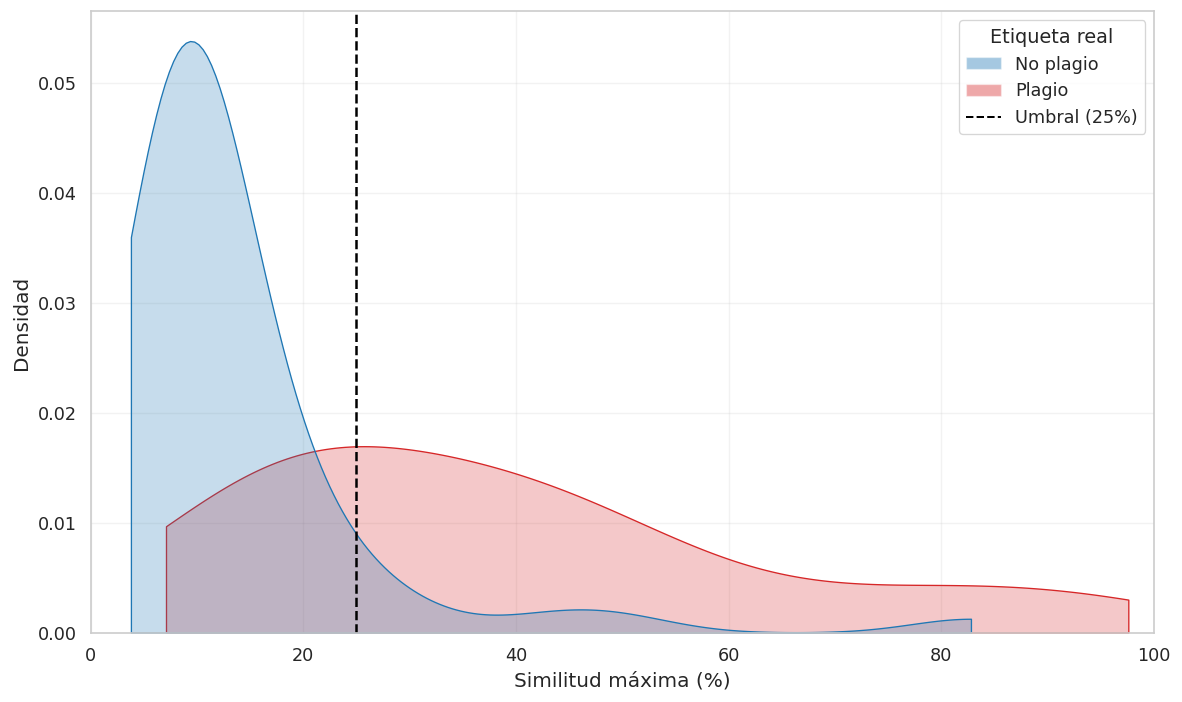

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.metrics import precision_score, recall_score, f1_score

# Crear copia para no modificar df2 directamente
df_plot = df2.copy()

# Convertir similitud a porcentaje si está en escala 0-1
if df_plot['sim_maxima'].max() <= 1:
    df_plot['sim_maxima_pct'] = df_plot['sim_maxima'] * 100
else:
    df_plot['sim_maxima_pct'] = df_plot['sim_maxima']

# Convertir similitud a porcentaje si está en escala 0-1
if df_plot['sim_levenshtein'].max() <= 1:
    df_plot['sim_levenshtein_pct'] = df_plot['sim_levenshtein'] * 100
else:
    df_plot['sim_levenshtein_pct'] = df_plot['sim_levenshtein']

# Convertir similitud a porcentaje si está en escala 0-1
if df_plot['sim_trigramas'].max() <= 1:
    df_plot['sim_trigramas_pct'] = df_plot['sim_trigramas'] * 100
else:
    df_plot['sim_trigramas_pct'] = df_plot['sim_trigramas']

# Umbral en porcentaje
umbral = 0.25
umbral_pct = umbral * 100

plt.figure(figsize=(10, 6))

sns.kdeplot(
    data=df_plot,
    x='sim_maxima_pct',
    hue='etiqueta_real',
    fill=True,
    common_norm=False,
    palette={
        'plagio': '#d62728',
        'no_plagio': '#1f77b4'
    },
    hue_order=['no_plagio', 'plagio'],
    clip=(0, 100),
    cut=0
)

plt.axvline(
    umbral_pct,
    color='black',
    linestyle='--',
    linewidth=1.5
)

plt.xlabel('Similitud máxima (%)', fontsize=12)
plt.ylabel('Densidad', fontsize=12)
plt.xlim(0, 100)

# Leyenda manual para que aparezca bien el umbral
legend_elements = [
    Patch(facecolor='#1f77b4', alpha=0.4, label='No plagio'),
    Patch(facecolor='#d62728', alpha=0.4, label='Plagio'),
    Line2D([0], [0], color='black', linestyle='--', label='Umbral (25%)')
]

plt.legend(
    handles=legend_elements,
    title='Etiqueta real',
    loc='upper right'
)

plt.tight_layout()
plt.show()


# -- Preparación de datos para los LLMs (Fase 2) --

modelos = [
    'deepseek-r1:32b',
    'llama3.1:8b',
    'llama3.2:3b',
    'phi4-mini:3.8b',
    'qwen3-vl:30b',
    'poligpt-code',
    'poligpt'
]

y_true = (df2['etiqueta_real'] == 'plagio').astype(int)

metricas = []

for m in modelos:
    y_pred = (df2[f'prediccion_{m}'] == 'plagio').astype(int)

    p = precision_score(y_true, y_pred, zero_division=0)
    r = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    metricas.append({
        'Modelo': m,
        'Precision': p,
        'Recall': r,
        'F1': f1
    })

df_metrics = pd.DataFrame(metricas).sort_values(by='Precision', ascending=False)

top_3_modelos = (
    df_metrics
    .sort_values(by='F1', ascending=False)
    ['Modelo']
    .head(3)
    .tolist()
)

In [83]:
# %%
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    accuracy_score,
    balanced_accuracy_score
)

# =========================
# Configuración general
# =========================

CSV_PATH = "resultados_comparativa_llm.csv"

UMBRAL_FASE1 = 0.25  # umbral elegido en dev set, escala 0-1

FIG_DIR = Path("figuras_tfg_plagio")
TAB_DIR = Path("tablas_tfg_plagio")

FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.15)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.family": "serif",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.titlesize": 12
})

PALETA_CLASES = {
    "no_plagio": "#B22222",
    "plagio": "#2F5597"
}

ORDEN_CLASES = ["no_plagio", "plagio"]


# %%
# =========================
# Carga y preparación
# =========================

df = pd.read_csv(CSV_PATH)

def normalizar_etiqueta(x):
    x = str(x).strip().lower()
    x = x.replace(" ", "_")

    if "no_plagio" in x or "no-plagio" in x:
        return "no_plagio"
    elif "plagio" in x:
        return "plagio"
    else:
        return "desconocido"


def convertir_bool(x):
    if isinstance(x, bool):
        return x

    x = str(x).strip().lower()

    if x in ["true", "1", "sí", "si", "yes"]:
        return True
    elif x in ["false", "0", "no"]:
        return False
    else:
        return np.nan


def ordenar_nivel(nivel):
    try:
        return int(str(nivel).split("_")[-1])
    except:
        return 999


def nombre_seguro(nombre):
    return (
        str(nombre)
        .replace(":", "_")
        .replace(".", "_")
        .replace("/", "_")
        .replace(" ", "_")
    )


def guardar_figura(nombre):
    plt.savefig(FIG_DIR / f"{nombre}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")


def guardar_tabla(tabla, nombre):
    tabla.to_csv(TAB_DIR / f"{nombre}.csv", index=False)
    tabla.to_latex(
        TAB_DIR / f"{nombre}.tex",
        index=False,
        float_format="%.3f",
        escape=True
    )


def calcular_metricas(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    especificidad = tn / (tn + fp) if (tn + fp) > 0 else np.nan

    return {
        "N": len(y_true),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "Especificidad": especificidad,
        "F0.5": fbeta_score(y_true, y_pred, beta=0.5, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "F2": fbeta_score(y_true, y_pred, beta=2, zero_division=0)
    }


df["etiqueta_real_norm"] = df["etiqueta_real"].apply(normalizar_etiqueta)
df["y_true"] = (df["etiqueta_real_norm"] == "plagio").astype(int)

modelos = [
    c.replace("prediccion_", "")
    for c in df.columns
    if c.startswith("prediccion_")
]

# Similitud en porcentaje
df["sim_maxima_num"] = pd.to_numeric(df["sim_maxima"], errors="coerce")
df["sim_levenshtein_num"] = pd.to_numeric(df["sim_levenshtein"], errors="coerce")
df["sim_trigramas_num"] = pd.to_numeric(df["sim_trigramas"], errors="coerce")

if df["sim_maxima_num"].max() <= 1.5:
    df["sim_maxima_pct"] = df["sim_maxima_num"] * 100
    umbral_pct = UMBRAL_FASE1 * 100
else:
    df["sim_maxima_pct"] = df["sim_maxima_num"]
    umbral_pct = UMBRAL_FASE1 * 100

if df["sim_levenshtein_num"].max() <= 1.5:
    df["sim_levenshtein_pct"] = df["sim_levenshtein_num"] * 100
else:
    df["sim_levenshtein_pct"] = df["sim_levenshtein_num"]

if df["sim_trigramas_num"].max() <= 1.5:
    df["sim_trigramas_pct"] = df["sim_trigramas_num"] * 100
else:
    df["sim_trigramas_pct"] = df["sim_trigramas_num"]

# Predicción de la fase 1
df["pred_fase1"] = df["sim_maxima_pct"] >= umbral_pct

# Si existe la columna ya calculada, se comprueba coherencia
if "pasa_filtro_matematico" in df.columns:
    df["pasa_filtro_matematico_bool"] = df["pasa_filtro_matematico"].apply(convertir_bool)

    diferencias = (
        df["pred_fase1"] != df["pasa_filtro_matematico_bool"]
    ).sum()

    if diferencias == 0:
        df["pred_fase1"] = df["pasa_filtro_matematico_bool"]
    else:
        print(f"Aviso: hay {diferencias} diferencias entre el umbral calculado y pasa_filtro_matematico.")


df["nivel"] = pd.Categorical(
    df["nivel"],
    categories=sorted(df["nivel"].dropna().unique(), key=ordenar_nivel),
    ordered=True
)

display(df.head())
print("Modelos detectados:", modelos)

,task_id,perfil,nivel,etiqueta_real,palabras_original,palabras_variante,ruta,sim_trigramas,sim_levenshtein,sim_maxima,...,etiqueta_real_norm,y_true,sim_maxima_num,sim_levenshtein_num,sim_trigramas_num,sim_maxima_pct,sim_levenshtein_pct,sim_trigramas_pct,pred_fase1,pasa_filtro_matematico_bool
0,cien_s1_t02,alto,nivel_0,plagio,37,37,filtro_matematico,100.0,100.0,100.0,...,plagio,1,100.0,100.0,100.0,100.0,100.0,100.0,True,True
1,cien_s1_t02,alto,nivel_1,plagio,37,37,filtro_matematico,89.2,35.1,89.2,...,plagio,1,89.2,35.1,89.2,89.2,35.1,89.2,True,True
2,cien_s1_t02,alto,nivel_2,plagio,37,37,filtro_matematico,40.0,86.5,86.5,...,plagio,1,86.5,86.5,40.0,86.5,86.5,40.0,True,True
3,cien_s1_t02,alto,nivel_3,plagio,37,34,filtro_matematico,36.7,67.6,67.6,...,plagio,1,67.6,67.6,36.7,67.6,67.6,36.7,True,True
4,cien_s1_t02,alto,nivel_4,no_plagio,37,39,filtro_matematico,4.3,30.8,30.8,...,no_plagio,0,30.8,30.8,4.3,30.8,30.8,4.3,True,True


Modelos detectados: ['deepseek-r1:32b', 'llama3.1:8b', 'llama3.2:3b', 'phi4-mini:3.8b', 'qwen3-vl:30b', 'poligpt-code', 'poligpt']


In [84]:
# %%
# =========================================================
# FASE 1: filtro léxico basado en similitud
# =========================================================

y_true = df["y_true"].astype(int)
y_pred_fase1 = df["pred_fase1"].astype(int)

metricas_fase1 = calcular_metricas(y_true, y_pred_fase1)

tabla_fase1_metricas = pd.DataFrame([{
    "Fase": "Filtro léxico",
    **metricas_fase1
}])

columnas_fase1 = [
    "Fase", "N", "TN", "FP", "FN", "TP",
    "Precision", "Recall", "Especificidad",
    "F2", "F1", "Accuracy", "Balanced accuracy"
]

tabla_fase1_metricas = tabla_fase1_metricas[columnas_fase1]

display(
    tabla_fase1_metricas.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "Especificidad": "{:.3f}",
        "F2": "{:.3f}",
        "F1": "{:.3f}",
        "Accuracy": "{:.3f}",
        "Balanced accuracy": "{:.3f}"
    })
)

guardar_tabla(tabla_fase1_metricas, "tabla_fase1_metricas")


# %%
# Matriz de confusión de la fase 1

cm_fase1 = confusion_matrix(y_true, y_pred_fase1, labels=[0, 1])

tabla_cm_fase1 = pd.DataFrame(
    cm_fase1,
    index=["Real: no plagio", "Real: plagio"],
    columns=["Predicción: no plagio", "Predicción: plagio"]
)

display(tabla_cm_fase1)

tabla_cm_fase1_reset = tabla_cm_fase1.reset_index().rename(columns={"index": "Clase real"})
guardar_tabla(tabla_cm_fase1_reset, "tabla_fase1_matriz_confusion")


# %%
# Tabla por nivel para la fase 1

filas_nivel_fase1 = []

for nivel, g in df.groupby("nivel", observed=True):
    yt = g["y_true"].astype(int)
    yp = g["pred_fase1"].astype(int)

    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()

    recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    tasa_fp = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    precision = tp / (tp + fp) if (tp + fp) > 0 else np.nan

    filas_nivel_fase1.append({
        "Nivel": nivel,
        "N": len(g),
        "Plagios reales": int(yt.sum()),
        "No plagios reales": int((yt == 0).sum()),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "Tasa FP": tasa_fp
    })

tabla_fase1_nivel = pd.DataFrame(filas_nivel_fase1)

display(
    tabla_fase1_nivel.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "Tasa FP": "{:.3f}"
    })
)

guardar_tabla(tabla_fase1_nivel, "tabla_fase1_por_nivel")

,Fase,N,TN,FP,FN,TP,Precision,Recall,Especificidad,F2,F1,Accuracy,Balanced accuracy
0,Filtro léxico,72,15,9,0,48,0.842,1.000,0.625,0.964,0.914,0.875,0.812


,Predicción: no plagio,Predicción: plagio
Real: no plagio,15,9
Real: plagio,0,48


,Nivel,N,Plagios reales,No plagios reales,TN,FP,FN,TP,Precision,Recall,Tasa FP
0,nivel_0,12,12,0,0,0,0,12,1.000,1.000,nan
1,nivel_1,12,12,0,0,0,0,12,1.000,1.000,nan
2,nivel_2,12,12,0,0,0,0,12,1.000,1.000,nan
3,nivel_3,12,12,0,0,0,0,12,1.000,1.000,nan
4,nivel_4,12,0,12,7,5,0,0,0.000,nan,0.417
5,nivel_5,12,0,12,8,4,0,0,0.000,nan,0.333


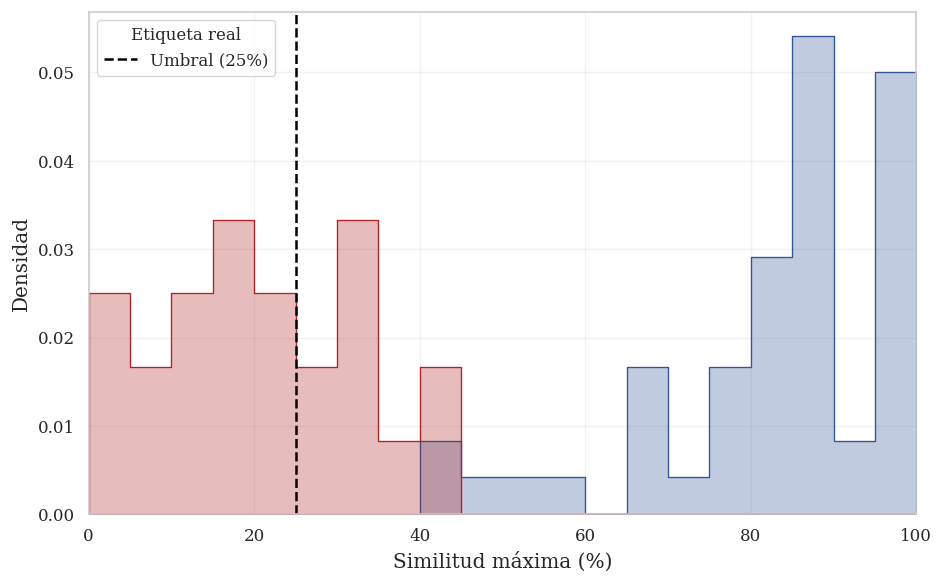

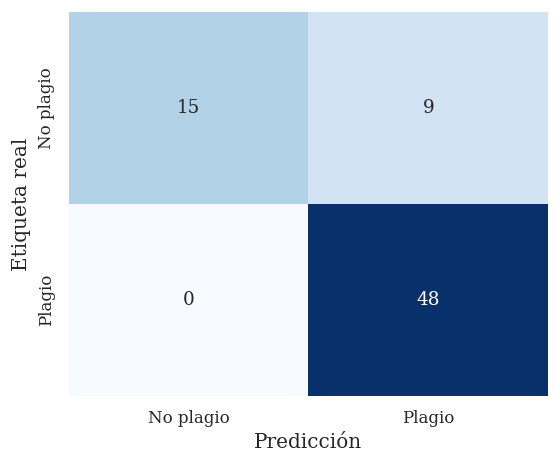

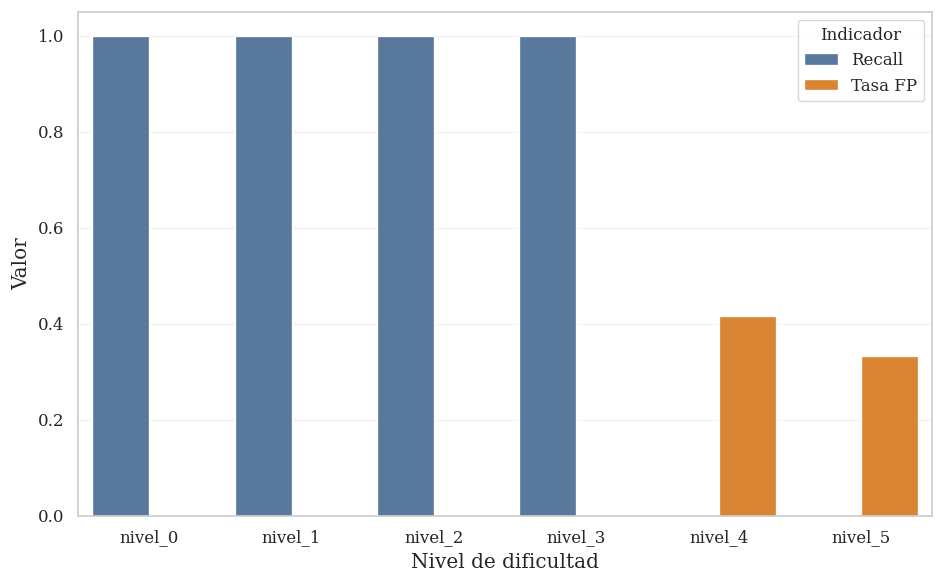

In [85]:
# %%
# Distribución de similitud máxima por clase real
PALETA_METRICAS = {
    "Precision": "#08306B",   # azul muy oscuro
    "Recall": "#2171B5",      # azul medio
    "F0.5": "#4292C6",        # azul claro-medio
    "F1": "#6BAED6",          # azul claro
    "F2": "#9ECAE1"           # azul muy claro
}
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sim_maxima_pct",
    hue="etiqueta_real_norm",
    hue_order=ORDEN_CLASES,
    bins=np.linspace(0, 100, 21),
    stat="density",
    common_norm=False,
    element="step",
    fill=True,
    alpha=0.30,
    palette=PALETA_CLASES
)

plt.axvline(
    umbral_pct,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral ({umbral_pct:.0f}%)"
)

plt.xlabel("Similitud máxima (%)")
plt.ylabel("Densidad")
plt.xlim(0, 100)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(title="Etiqueta real")

plt.tight_layout()
guardar_figura("fase1_distribucion_similitud")
plt.show()


# %%
# Matriz de confusión de fase 1

plt.figure(figsize=(4.8, 4))

sns.heatmap(
    cm_fase1,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["No plagio", "Plagio"],
    yticklabels=["No plagio", "Plagio"]
)

plt.xlabel("Predicción")
plt.ylabel("Etiqueta real")

plt.tight_layout()
guardar_figura("fase1_matriz_confusion")
plt.show()


# %%
# Recall y tasa de falsos positivos por nivel en fase 1

plot_fase1_nivel = tabla_fase1_nivel.melt(
    id_vars="Nivel",
    value_vars=["Recall", "Tasa FP"],
    var_name="Indicador",
    value_name="Valor"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_fase1_nivel,
    x="Nivel",
    y="Valor",
    hue="Indicador",
    palette=["#4C78A8", "#F58518"]
)

plt.xlabel("Nivel de dificultad")
plt.ylabel("Valor")
plt.ylim(0, 1.05)
plt.legend(title="Indicador")

plt.tight_layout()
guardar_figura("fase1_recall_tasa_fp_por_nivel")
plt.show()

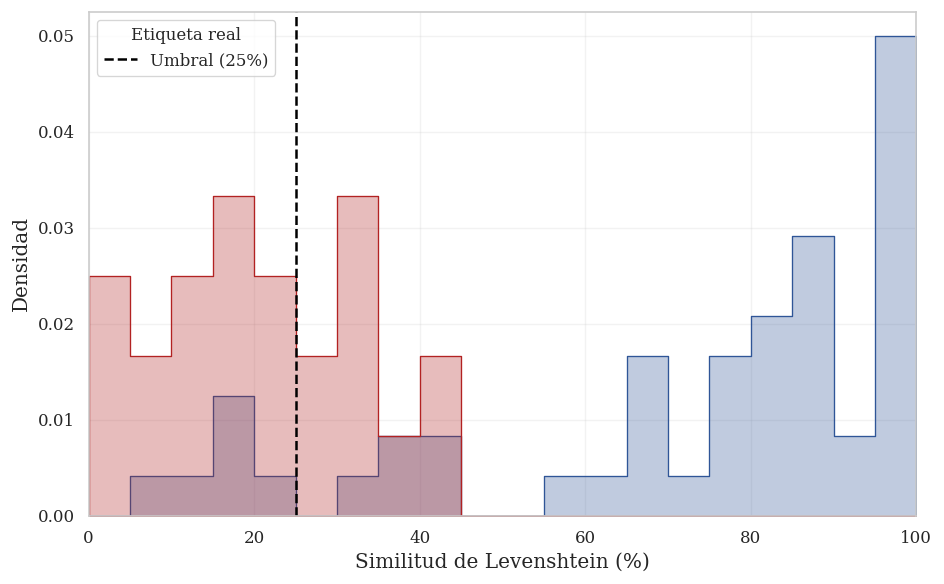

In [86]:

PALETA_METRICAS = {
    "Precision": "#08306B",   # azul muy oscuro
    "Recall": "#2171B5",      # azul medio
    "F0.5": "#4292C6",        # azul claro-medio
    "F1": "#6BAED6",          # azul claro
    "F2": "#9ECAE1"           # azul muy claro
}
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sim_levenshtein_pct",
    hue="etiqueta_real_norm",
    hue_order=ORDEN_CLASES,
    bins=np.linspace(0, 100, 21),
    stat="density",
    common_norm=False,
    element="step",
    fill=True,
    alpha=0.30,
    palette=PALETA_CLASES
)

plt.axvline(
    umbral_pct,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral ({umbral_pct:.0f}%)"
)

plt.xlabel("Similitud de Levenshtein (%)")
plt.ylabel("Densidad")
plt.xlim(0, 100)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(title="Etiqueta real")

plt.tight_layout()
guardar_figura("fase1_distribucion_similitud")
plt.show()

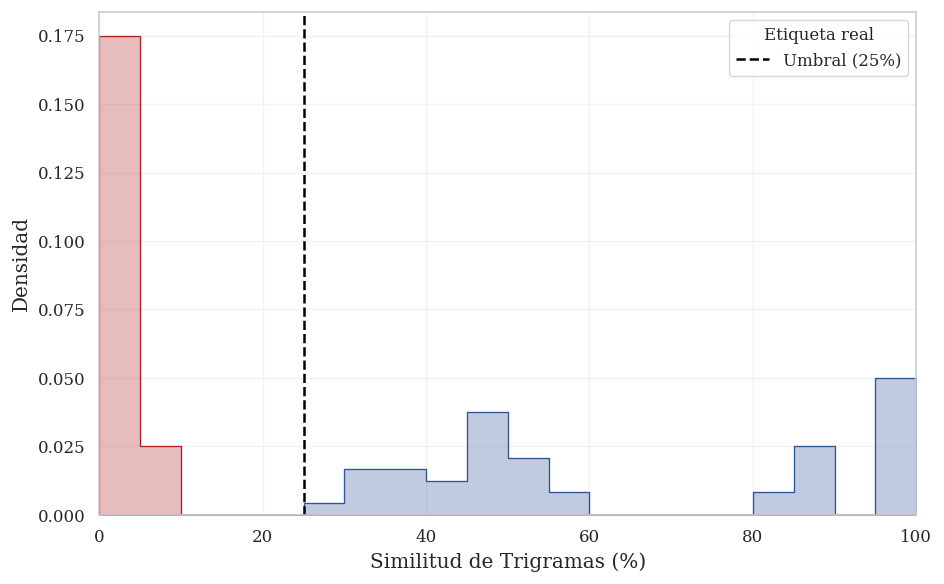

In [87]:
PALETA_METRICAS = {
    "Precision": "#08306B",   # azul muy oscuro
    "Recall": "#2171B5",      # azul medio
    "F0.5": "#4292C6",        # azul claro-medio
    "F1": "#6BAED6",          # azul claro
    "F2": "#9ECAE1"           # azul muy claro
}
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="sim_trigramas_pct",
    hue="etiqueta_real_norm",
    hue_order=ORDEN_CLASES,
    bins=np.linspace(0, 100, 21),
    stat="density",
    common_norm=False,
    element="step",
    fill=True,
    alpha=0.30,
    palette=PALETA_CLASES
)

plt.axvline(
    umbral_pct,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Umbral ({umbral_pct:.0f}%)"
)

plt.xlabel("Similitud de Trigramas (%)")
plt.ylabel("Densidad")
plt.xlim(0, 100)

handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(title="Etiqueta real")

plt.tight_layout()
guardar_figura("fase1_distribucion_similitud")
plt.show()

In [88]:
# %%
# =========================================================
# FASE 2: modelos LLM sobre los candidatos filtrados
# =========================================================
PALETA_METRICAS = {
    "Precision": "#4C78A8",   # azul apagado
    "Recall": "#59A14F",      # verde apagado
    "F0.5": "#B07AA1",        # morado suave
    "F1": "#F28E2B",          # naranja suave
    "F2": "#9C755F"           # marrón suave
}

df_fase2 = df[df["pred_fase1"] == True].copy()
y_true_fase2 = df_fase2["y_true"].astype(int)

filas_fase2 = []

for m in modelos:
    col_pred = f"prediccion_{m}"
    col_tiempo = f"tiempo_{m}"

    y_pred_modelo = (
        df_fase2[col_pred]
        .apply(normalizar_etiqueta)
        .eq("plagio")
        .astype(int)
    )

    met = calcular_metricas(y_true_fase2, y_pred_modelo)

    tiempo_medio = pd.to_numeric(df_fase2[col_tiempo], errors="coerce").mean()
    tiempo_mediano = pd.to_numeric(df_fase2[col_tiempo], errors="coerce").median()

    filas_fase2.append({
        "Modelo": m,
        **met,
        "Tiempo medio (s)": tiempo_medio,
        "Tiempo mediano (s)": tiempo_mediano
    })

tabla_fase2_metricas = pd.DataFrame(filas_fase2)

tabla_fase2_metricas = tabla_fase2_metricas.sort_values(
    by=["Precision", "F0.5", "F1", "Recall"],
    ascending=False
).reset_index(drop=True)

columnas_fase2 = [
    "Modelo", "N", "TN", "FP", "FN", "TP",
    "Precision", "Recall", "Especificidad",
    "F0.5", "F1", "Accuracy", "Balanced accuracy",
    "Tiempo medio (s)", "Tiempo mediano (s)"
]

tabla_fase2_metricas = tabla_fase2_metricas[columnas_fase2]

display(
    tabla_fase2_metricas.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "Especificidad": "{:.3f}",
        "F0.5": "{:.3f}",
        "F1": "{:.3f}",
        "Accuracy": "{:.3f}",
        "Balanced accuracy": "{:.3f}",
        "Tiempo medio (s)": "{:.2f}",
        "Tiempo mediano (s)": "{:.2f}"
    })
)

guardar_tabla(tabla_fase2_metricas, "tabla_fase2_metricas_modelos")

top_3_fase2 = tabla_fase2_metricas["Modelo"].head(3).tolist()
best_model_fase2 = top_3_fase2[0]

print("Mejor modelo fase 2:", best_model_fase2)
print("Top 3 fase 2:", top_3_fase2)

,Modelo,N,TN,FP,FN,TP,Precision,Recall,Especificidad,F0.5,F1,Accuracy,Balanced accuracy,Tiempo medio (s),Tiempo mediano (s)
0,poligpt-code,57,9,0,1,47,1.000,0.979,1.000,0.996,0.989,0.982,0.990,16.90,16.46
1,poligpt,57,9,0,1,47,1.000,0.979,1.000,0.996,0.989,0.982,0.990,7.20,7.15
2,deepseek-r1:32b,57,9,0,15,33,1.000,0.688,1.000,0.917,0.815,0.737,0.844,130.27,201.08
3,phi4-mini:3.8b,57,9,0,42,6,1.000,0.125,1.000,0.417,0.222,0.263,0.562,21.43,28.10
4,llama3.1:8b,57,8,1,27,21,0.955,0.438,0.889,0.772,0.600,0.509,0.663,34.73,48.91
5,qwen3-vl:30b,57,0,9,0,48,0.842,1.000,0.000,0.870,0.914,0.842,0.500,4.64,4.66
6,llama3.2:3b,57,1,8,7,41,0.837,0.854,0.111,0.840,0.845,0.737,0.483,12.03,11.60


Mejor modelo fase 2: poligpt-code
Top 3 fase 2: ['poligpt-code', 'poligpt', 'deepseek-r1:32b']


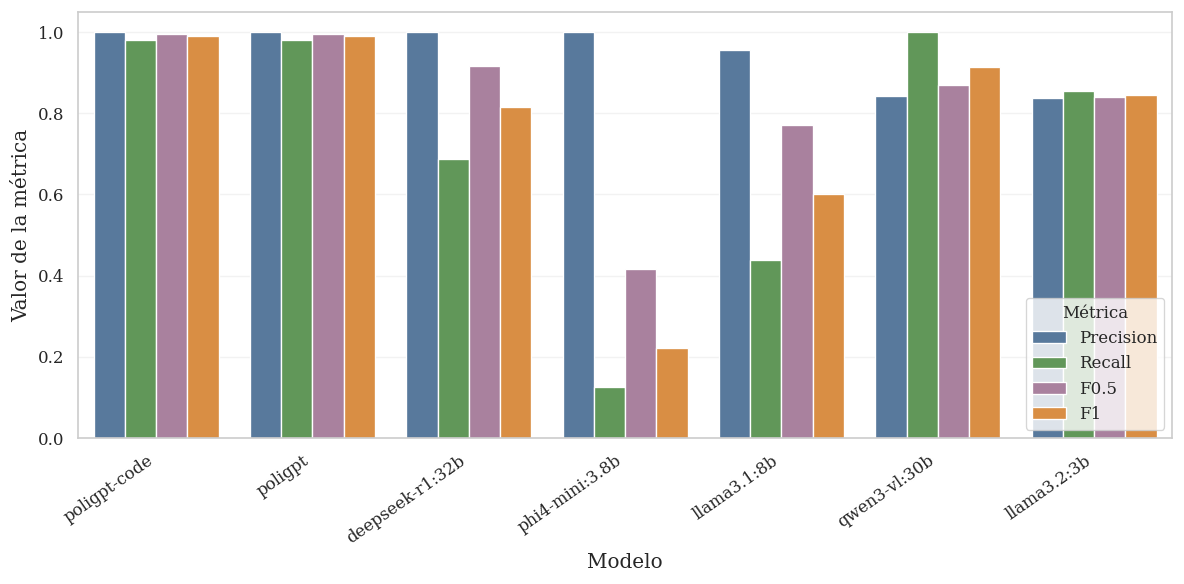

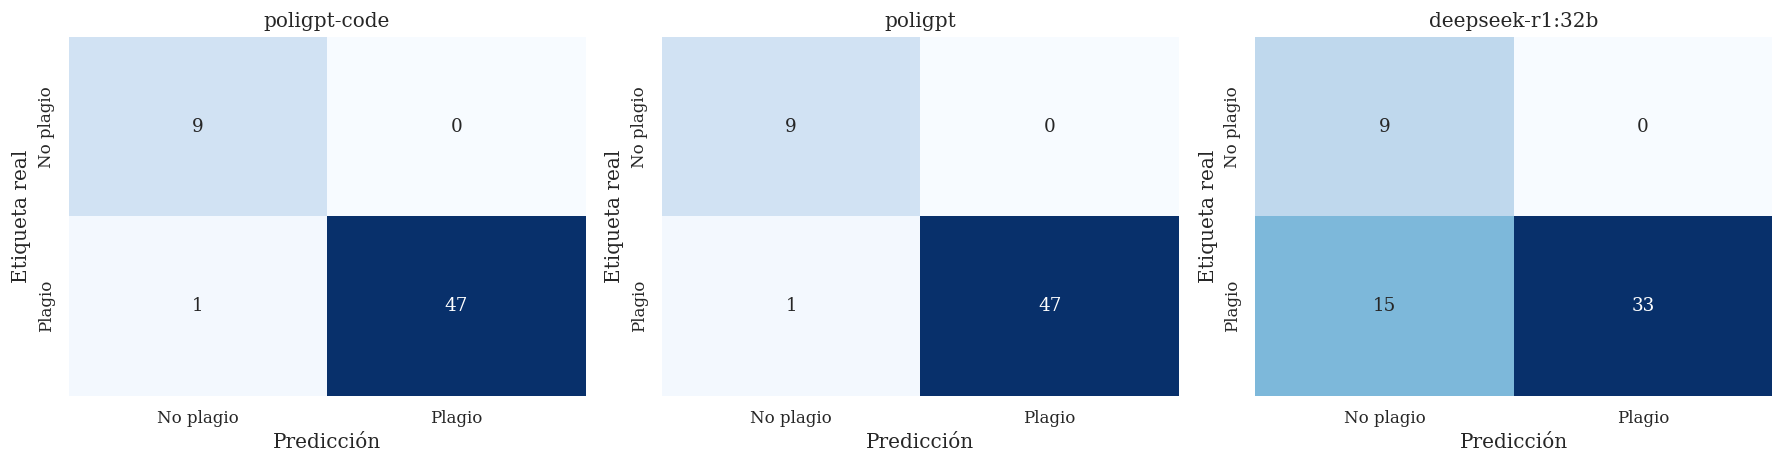

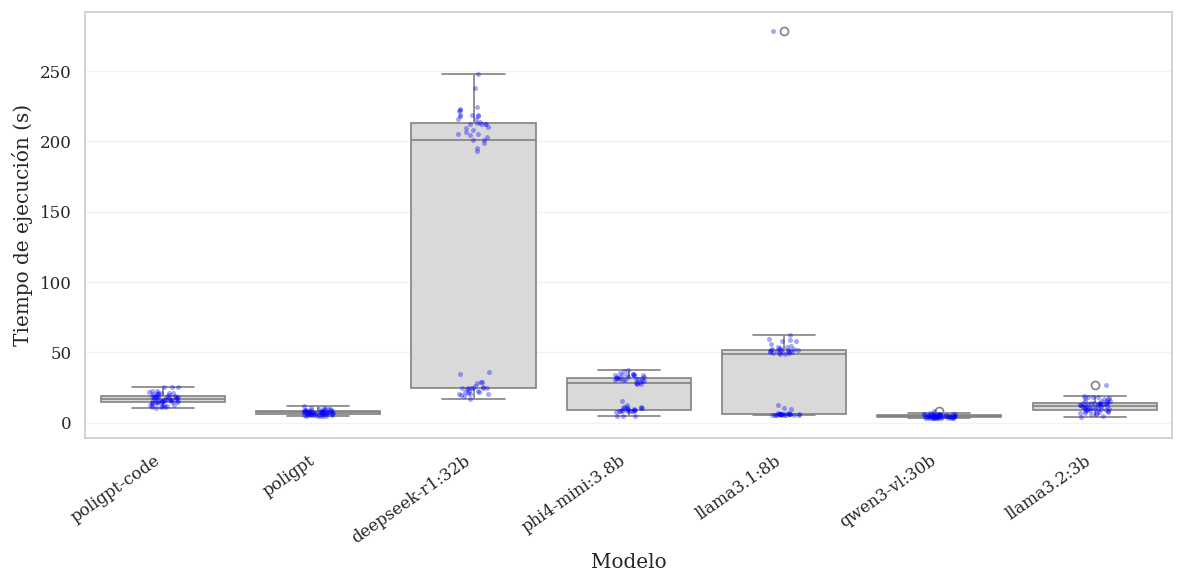

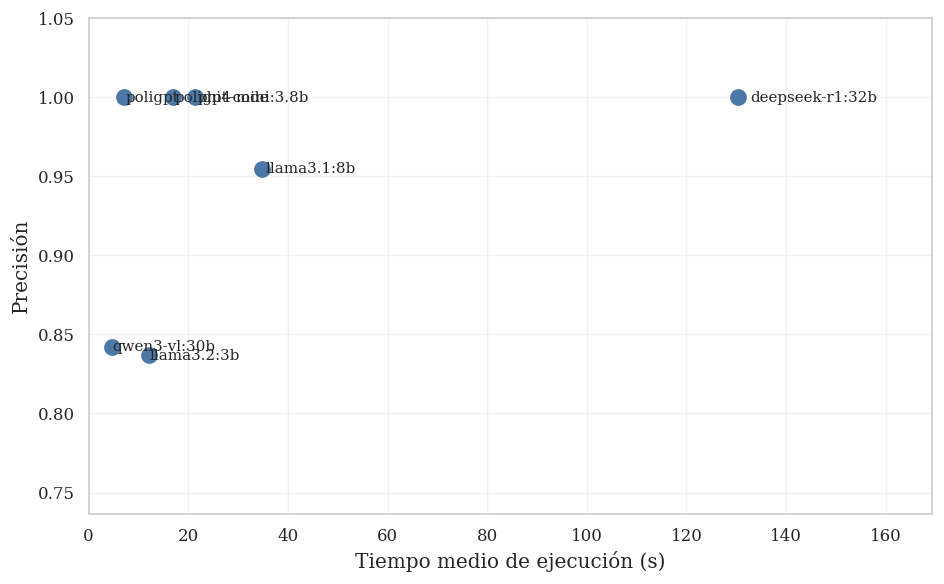

In [89]:
# %%
# Métricas de fase 2 por modelo

metricas_plot_fase2 = tabla_fase2_metricas.melt(
    id_vars="Modelo",
    value_vars=["Precision", "Recall", "F0.5", "F1"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=metricas_plot_fase2,
    x="Modelo",
    y="Valor",
    hue="Métrica",
    order=tabla_fase2_metricas["Modelo"],
    palette=PALETA_METRICAS
)

plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Métrica", loc="lower right")

plt.tight_layout()
guardar_figura("fase2_metricas_modelos")
plt.show()


# %%
# Matrices de confusión de los tres mejores modelos de fase 2

fig, axes = plt.subplots(1, len(top_3_fase2), figsize=(5 * len(top_3_fase2), 4))

if len(top_3_fase2) == 1:
    axes = [axes]

for ax, m in zip(axes, top_3_fase2):
    y_pred_modelo = (
        df_fase2[f"prediccion_{m}"]
        .apply(normalizar_etiqueta)
        .eq("plagio")
        .astype(int)
    )

    cm = confusion_matrix(y_true_fase2, y_pred_modelo, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["No plagio", "Plagio"],
        yticklabels=["No plagio", "Plagio"]
    )

    ax.set_title(m)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.tight_layout()
guardar_figura("fase2_matrices_confusion_top3")
plt.show()


# %%
# Coste temporal de los modelos en fase 2

tiempos_fase2 = []

for m in modelos:
    col_tiempo = f"tiempo_{m}"

    temp = pd.DataFrame({
        "Modelo": m,
        "Tiempo (s)": pd.to_numeric(df_fase2[col_tiempo], errors="coerce")
    })

    tiempos_fase2.append(temp)

df_tiempos_fase2 = pd.concat(tiempos_fase2, ignore_index=True)

plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df_tiempos_fase2,
    x="Modelo",
    y="Tiempo (s)",
    order=tabla_fase2_metricas["Modelo"],
    color="#D9D9D9"
)

sns.stripplot(
    data=df_tiempos_fase2,
    x="Modelo",
    y="Tiempo (s)",
    order=tabla_fase2_metricas["Modelo"],
    color="blue",
    alpha=0.35,
    size=3
)

plt.xlabel("Modelo")
plt.ylabel("Tiempo de ejecución (s)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
guardar_figura("fase2_tiempos_modelos")
plt.show()


# %%
# Relación entre precisión y tiempo medio

df_tradeoff_fase2 = tabla_fase2_metricas[[
    "Modelo", "Precision", "Recall", "F0.5", "F1", "Tiempo medio (s)"
]].copy()

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_tradeoff_fase2,
    x="Tiempo medio (s)",
    y="Precision",
    s=120,
    color="#4C78A8"
)

for _, row in df_tradeoff_fase2.iterrows():
    plt.text(
        row["Tiempo medio (s)"] * 1.02,
        row["Precision"],
        row["Modelo"],
        fontsize=9,
        va="center"
    )

plt.xlabel("Tiempo medio de ejecución (s)")
plt.ylabel("Precisión")
plt.ylim(max(0, df_tradeoff_fase2["Precision"].min() - 0.1), 1.05)
plt.xlim(0, df_tradeoff_fase2["Tiempo medio (s)"].max() * 1.30)

plt.tight_layout()
guardar_figura("fase2_precision_tiempo")
plt.show()

In [90]:
# %%
# =========================================================
# SISTEMA COMPLETO: fase 1 + fase 2
# =========================================================

filas_sistema = []

for m in modelos:
    pred_llm = (
        df[f"prediccion_{m}"]
        .apply(normalizar_etiqueta)
        .eq("plagio")
        .astype(int)
    )

    # Si no pasa fase 1, el sistema final predice no plagio.
    # Si pasa fase 1, se usa la predicción del LLM.
    pred_final = np.where(df["pred_fase1"], pred_llm, 0).astype(int)

    df[f"pred_final_{m}"] = pred_final

    met = calcular_metricas(y_true, pred_final)

    filas_sistema.append({
        "Modelo": m,
        **met
    })

tabla_sistema_metricas = pd.DataFrame(filas_sistema)

tabla_sistema_metricas = tabla_sistema_metricas.sort_values(
    by=["Precision", "F0.5", "F1", "Recall"],
    ascending=False
).reset_index(drop=True)

columnas_sistema = [
    "Modelo", "N", "TN", "FP", "FN", "TP",
    "Precision", "Recall", "Especificidad",
    "F0.5", "F1", "F2", "Accuracy", "Balanced accuracy"
]

tabla_sistema_metricas = tabla_sistema_metricas[columnas_sistema]

display(
    tabla_sistema_metricas.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "Especificidad": "{:.3f}",
        "F0.5": "{:.3f}",
        "F1": "{:.3f}",
        "F2": "{:.3f}",
        "Accuracy": "{:.3f}",
        "Balanced accuracy": "{:.3f}"
    })
)

guardar_tabla(tabla_sistema_metricas, "tabla_sistema_completo_metricas")

top_3_sistema = tabla_sistema_metricas["Modelo"].head(3).tolist()
best_model_sistema = top_3_sistema[0]

print("Mejor modelo sistema completo:", best_model_sistema)
print("Top 3 sistema completo:", top_3_sistema)

,Modelo,N,TN,FP,FN,TP,Precision,Recall,Especificidad,F0.5,F1,F2,Accuracy,Balanced accuracy
0,poligpt-code,72,24,0,1,47,1.000,0.979,1.000,0.996,0.989,0.983,0.986,0.990
1,poligpt,72,24,0,1,47,1.000,0.979,1.000,0.996,0.989,0.983,0.986,0.990
2,deepseek-r1:32b,72,24,0,15,33,1.000,0.688,1.000,0.917,0.815,0.733,0.792,0.844
3,phi4-mini:3.8b,72,24,0,42,6,1.000,0.125,1.000,0.417,0.222,0.152,0.417,0.562
4,llama3.1:8b,72,23,1,27,21,0.955,0.438,0.958,0.772,0.600,0.491,0.611,0.698
5,qwen3-vl:30b,72,15,9,0,48,0.842,1.000,0.625,0.870,0.914,0.964,0.875,0.812
6,llama3.2:3b,72,16,8,7,41,0.837,0.854,0.667,0.840,0.845,0.851,0.792,0.760


Mejor modelo sistema completo: poligpt-code
Top 3 sistema completo: ['poligpt-code', 'poligpt', 'deepseek-r1:32b']


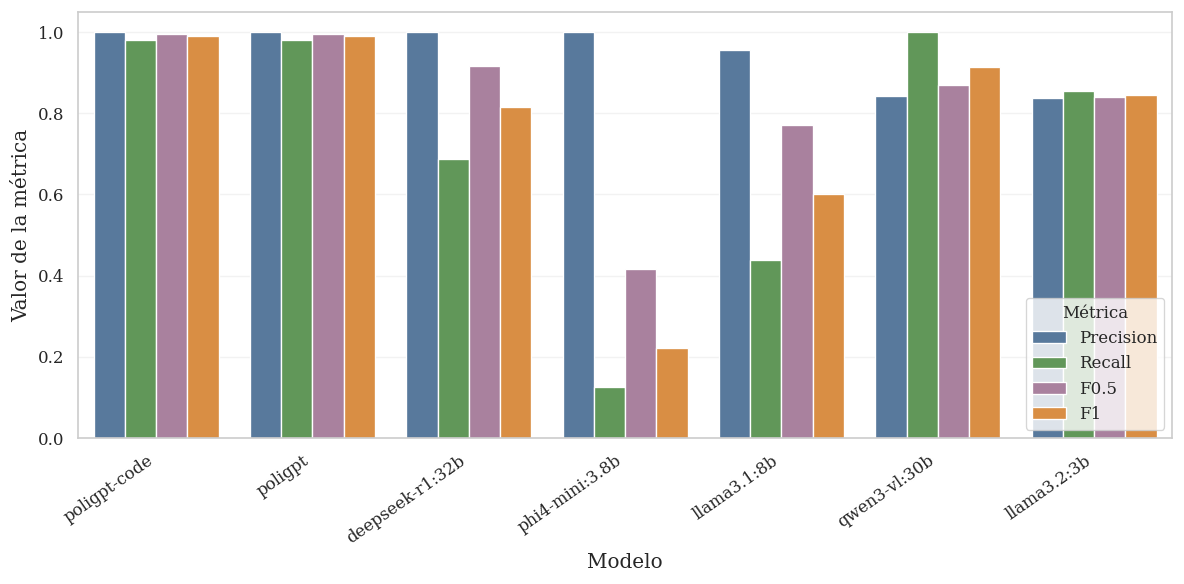

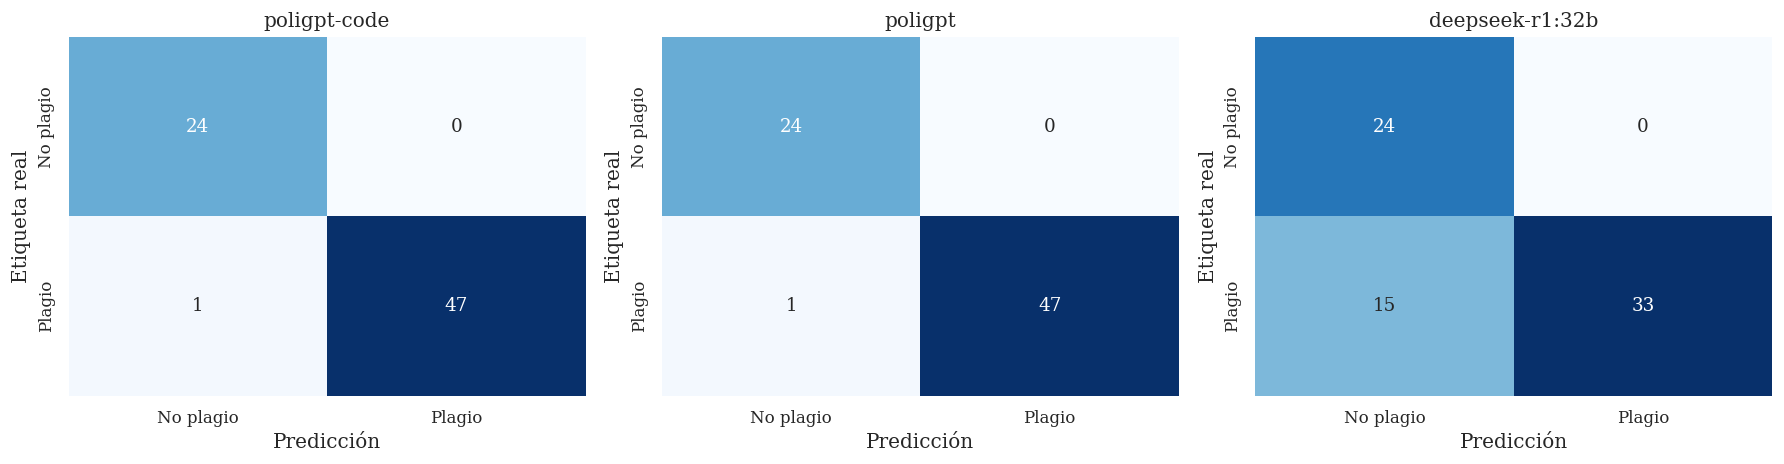

,Evaluación,Modelo,N,TN,FP,FN,TP,Precision,Recall,Especificidad,F0.5,F1,F2,Accuracy,Balanced accuracy
0,Fase 1,Filtro léxico,72,15,9,0,48,0.842,1.000,0.625,0.870,0.914,0.964,0.875,0.812
1,Sistema completo,poligpt-code,72,24,0,1,47,1.000,0.979,1.000,0.996,0.989,0.983,0.986,0.990


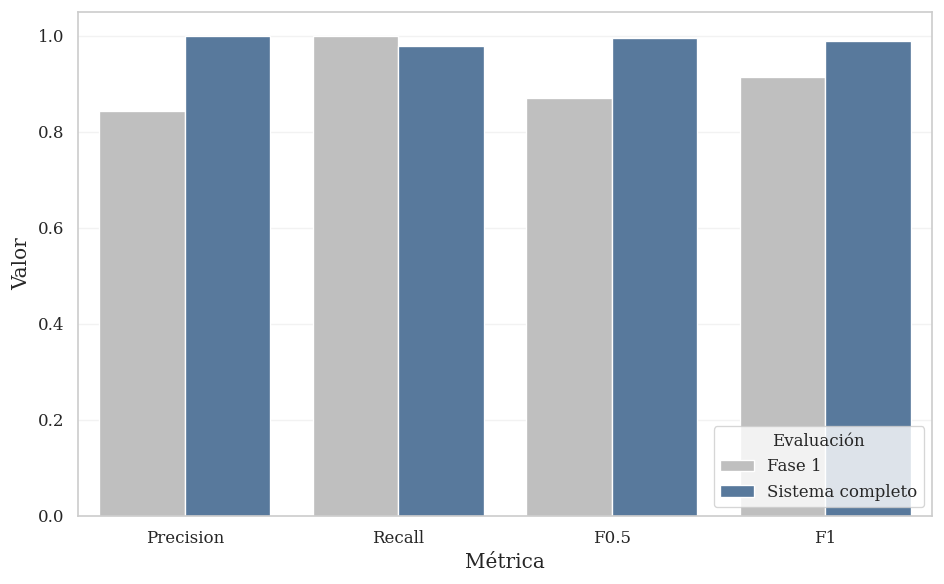

,nivel,etiqueta_real_norm,N,Tasa de acierto
0,nivel_0,plagio,12,1.000
1,nivel_1,plagio,12,1.000
2,nivel_2,plagio,12,0.917
3,nivel_3,plagio,12,1.000
4,nivel_4,no_plagio,12,1.000
5,nivel_5,no_plagio,12,1.000


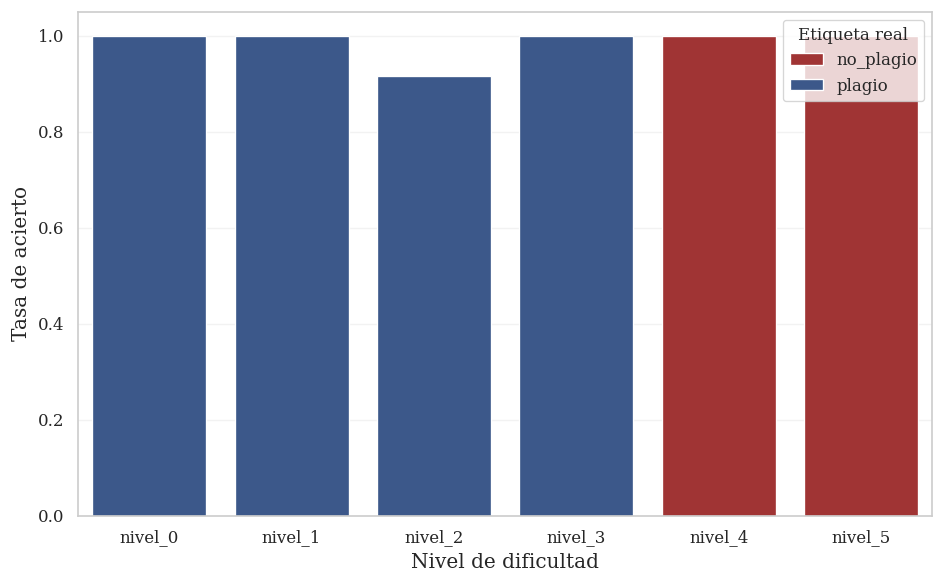

In [91]:
# %%
# Métricas del sistema completo por modelo
PALETA_METRICAS = {
    "Precision": "#4C78A8",   # azul apagado
    "Recall": "#59A14F",      # verde apagado
    "F0.5": "#B07AA1",        # morado suave
    "F1": "#F28E2B",          # naranja suave
    "F2": "#9C755F"           # marrón suave
}

metricas_plot_sistema = tabla_sistema_metricas.melt(
    id_vars="Modelo",
    value_vars=["Precision", "Recall", "F0.5", "F1"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=metricas_plot_sistema,
    x="Modelo",
    y="Valor",
    hue="Métrica",
    order=tabla_sistema_metricas["Modelo"],
    palette=PALETA_METRICAS
)

plt.xlabel("Modelo")
plt.ylabel("Valor de la métrica")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.legend(title="Métrica", loc="lower right")

plt.tight_layout()
guardar_figura("sistema_completo_metricas_modelos")
plt.show()


# %%
# Matrices de confusión del sistema completo para los tres mejores modelos

fig, axes = plt.subplots(1, len(top_3_sistema), figsize=(5 * len(top_3_sistema), 4))

if len(top_3_sistema) == 1:
    axes = [axes]

for ax, m in zip(axes, top_3_sistema):
    y_pred_final = df[f"pred_final_{m}"].astype(int)

    cm = confusion_matrix(y_true, y_pred_final, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        ax=ax,
        xticklabels=["No plagio", "Plagio"],
        yticklabels=["No plagio", "Plagio"]
    )

    ax.set_title(m)
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Etiqueta real")

plt.tight_layout()
guardar_figura("sistema_completo_matrices_confusion_top3")
plt.show()


# %%
# Comparación entre fase 1 y sistema completo con el mejor modelo

met_fase1 = calcular_metricas(y_true, y_pred_fase1)

met_sistema_best = calcular_metricas(
    y_true,
    df[f"pred_final_{best_model_sistema}"].astype(int)
)

tabla_comparacion_fases = pd.DataFrame([
    {
        "Evaluación": "Fase 1",
        "Modelo": "Filtro léxico",
        **met_fase1
    },
    {
        "Evaluación": "Sistema completo",
        "Modelo": best_model_sistema,
        **met_sistema_best
    }
])

tabla_comparacion_fases = tabla_comparacion_fases[[
    "Evaluación", "Modelo", "N", "TN", "FP", "FN", "TP",
    "Precision", "Recall", "Especificidad",
    "F0.5", "F1", "F2", "Accuracy", "Balanced accuracy"
]]

display(
    tabla_comparacion_fases.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "Especificidad": "{:.3f}",
        "F0.5": "{:.3f}",
        "F1": "{:.3f}",
        "F2": "{:.3f}",
        "Accuracy": "{:.3f}",
        "Balanced accuracy": "{:.3f}"
    })
)

guardar_tabla(tabla_comparacion_fases, "tabla_comparacion_fase1_sistema_completo")


# %%
# Comparación visual entre fase 1 y sistema completo

plot_comparacion = tabla_comparacion_fases.melt(
    id_vars=["Evaluación", "Modelo"],
    value_vars=["Precision", "Recall", "F0.5", "F1"],
    var_name="Métrica",
    value_name="Valor"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_comparacion,
    x="Métrica",
    y="Valor",
    hue="Evaluación",
    palette=["#BFBFBF", "#4C78A8"]
)

plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1.05)
plt.legend(title="Evaluación", loc="lower right")

plt.tight_layout()
guardar_figura("comparacion_fase1_sistema_completo")
plt.show()


# %%
# Acierto del sistema completo por nivel y clase real

df_acierto_sistema = df.copy()

df_acierto_sistema["acierto_sistema"] = (
    df_acierto_sistema[f"pred_final_{best_model_sistema}"].astype(int)
    == df_acierto_sistema["y_true"].astype(int)
).astype(int)

tabla_acierto_nivel_sistema = (
    df_acierto_sistema
    .groupby(["nivel", "etiqueta_real_norm"], observed=True)["acierto_sistema"]
    .agg(["count", "mean"])
    .reset_index()
    .rename(columns={
        "count": "N",
        "mean": "Tasa de acierto"
    })
)

display(
    tabla_acierto_nivel_sistema.style.format({
        "Tasa de acierto": "{:.3f}"
    })
)

guardar_tabla(tabla_acierto_nivel_sistema, "tabla_sistema_completo_acierto_por_nivel")


plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_acierto_sistema,
    x="nivel",
    y="acierto_sistema",
    hue="etiqueta_real_norm",
    hue_order=ORDEN_CLASES,
    errorbar=None,
    palette=PALETA_CLASES
)

plt.xlabel("Nivel de dificultad")
plt.ylabel("Tasa de acierto")
plt.ylim(0, 1.05)
plt.legend(title="Etiqueta real")

plt.tight_layout()
guardar_figura("sistema_completo_acierto_por_nivel")
plt.show()

In [92]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# ==========================================================
# Configuración general
# ==========================================================

CSV_PATH = "resultados_clough_ancho.csv"

UMBRAL = 0.25
UMBRAL_PCT = UMBRAL * 100

MODELO_FINAL = "poligpt"   # Cambia aquí el modelo si quieres usar otro
GUARDAR = False            # Pon True si quieres guardar las figuras
OUT_DIR = "figuras_tfg_plagio"

df = pd.read_csv(CSV_PATH)

# ==========================================================
# Estética común para TFG
# ==========================================================

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "legend.fontsize": 10,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linestyle": "--",
    "figure.dpi": 120,
})

COLOR_PLAGIO = "#4C78A8"
COLOR_NO_PLAGIO = "#D95F02"
COLOR_GRIS = "#6E6E6E"
COLOR_UMBRAL = "#333333"

orden_categorias = ["cut", "light", "heavy", "non"]
orden_categorias = [c for c in orden_categorias if c in df["nivel"].unique()]

nombres_categorias = {
    "cut": "Cut",
    "light": "Light",
    "heavy": "Heavy",
    "non": "Non"
}

# ==========================================================
# Funciones auxiliares
# ==========================================================

def normalizar_etiqueta(x):
    x = str(x).strip().lower()
    if x in ["plagio", "1", "true", "si", "sí"]:
        return "plagio"
    if x in ["no_plagio", "no plagio", "0", "false", "no"]:
        return "no_plagio"
    return x


def metricas_binarias(y_true, y_pred):
    y_true = pd.Series(y_true).apply(normalizar_etiqueta)
    y_pred = pd.Series(y_pred).apply(normalizar_etiqueta)

    tp = int(((y_true == "plagio") & (y_pred == "plagio")).sum())
    tn = int(((y_true == "no_plagio") & (y_pred == "no_plagio")).sum())
    fp = int(((y_true == "no_plagio") & (y_pred == "plagio")).sum())
    fn = int(((y_true == "plagio") & (y_pred == "no_plagio")).sum())

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Accuracy": accuracy,
    }


def prediccion_sistema_completo(df, modelo):
    pred_col = f"prediccion_{modelo}"

    if pred_col not in df.columns:
        raise ValueError(f"No existe la columna {pred_col}. Revisa el nombre del modelo.")

    pred_modelo = df[pred_col].apply(normalizar_etiqueta)

    pred_final = np.where(
        df["pasa_filtro_matematico"],
        pred_modelo,
        "no_plagio"
    )

    return pd.Series(pred_final, index=df.index)


def finalizar_figura(nombre=None):
    plt.tight_layout()

    if GUARDAR and nombre is not None:
        import os
        os.makedirs(OUT_DIR, exist_ok=True)
        plt.savefig(f"{OUT_DIR}/{nombre}.pdf", bbox_inches="tight")
        plt.savefig(f"{OUT_DIR}/{nombre}.png", dpi=300, bbox_inches="tight")

    plt.show()


df["etiqueta_real"] = df["etiqueta_real"].apply(normalizar_etiqueta)

# En tu CSV sim_maxima ya está en porcentaje
df["sim_pct"] = df["sim_maxima"]

/tmp/ipykernel_468996/457685503.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


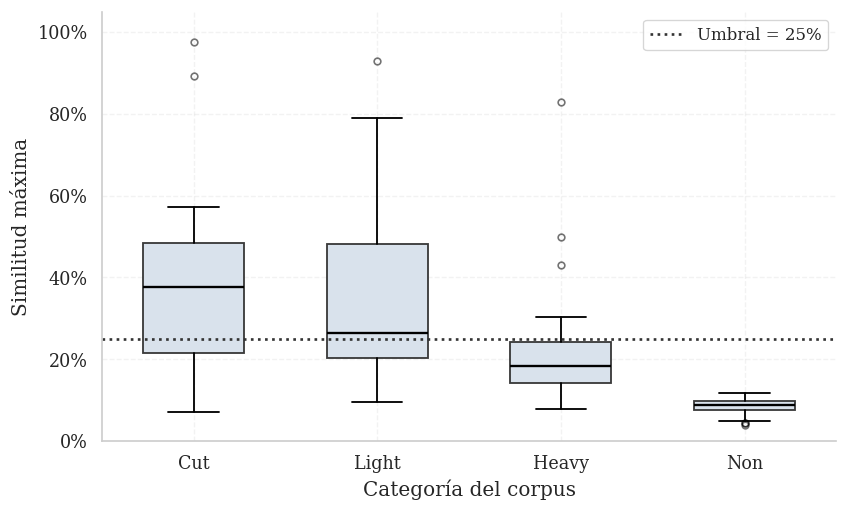

In [93]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))

datos_boxplot = [
    df.loc[df["nivel"] == cat, "sim_pct"].dropna()
    for cat in orden_categorias
]

bp = ax.boxplot(
    datos_boxplot,
    labels=[nombres_categorias[c] for c in orden_categorias],
    patch_artist=True,
    widths=0.55,
    showfliers=True,
    medianprops={"color": "black", "linewidth": 1.4},
    boxprops={"linewidth": 1.1},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1},
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.55},
)

for patch in bp["boxes"]:
    patch.set_facecolor("#D9E2EC")
    patch.set_edgecolor("#3A3A3A")

ax.axhline(
    UMBRAL_PCT,
    linestyle=":",
    linewidth=1.6,
    color=COLOR_UMBRAL,
    label=f"Umbral = {UMBRAL_PCT:.0f}%"
)

ax.set_xlabel("Categoría del corpus")
ax.set_ylabel("Similitud máxima")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, 105)
ax.legend(frameon=True, loc="upper right")

finalizar_figura("clough_distribucion_similitud_categoria")

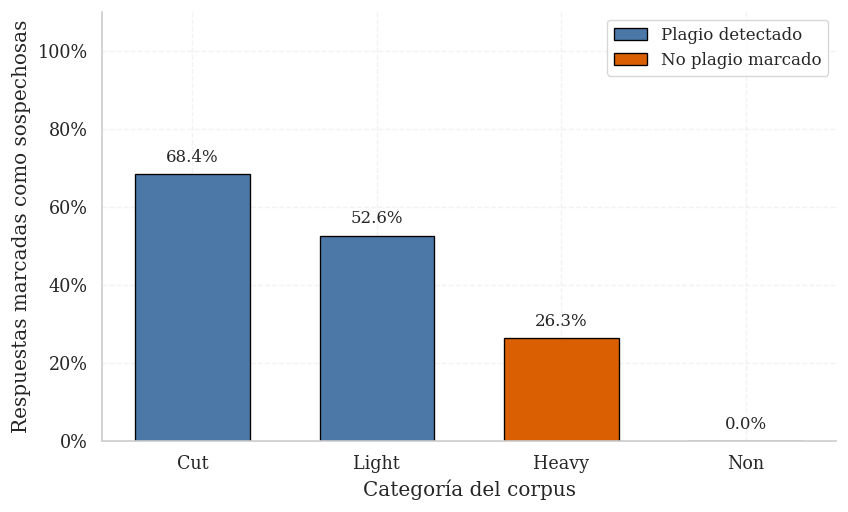

In [94]:
tasas = (
    df.groupby("nivel")["pasa_filtro_matematico"]
    .mean()
    .reindex(orden_categorias)
    * 100
)

fig, ax = plt.subplots(figsize=(7.2, 4.4))

leyendas_usadas = set()

for i, cat in enumerate(orden_categorias):
    etiqueta = df.loc[df["nivel"] == cat, "etiqueta_real"].mode().iloc[0]

    if etiqueta == "plagio":
        color = COLOR_PLAGIO
        label = "Plagio detectado"
    else:
        color = COLOR_NO_PLAGIO
        label = "No plagio marcado"

    if label in leyendas_usadas:
        label = None
    else:
        leyendas_usadas.add(label)

    ax.bar(
        i,
        tasas.loc[cat],
        color=color,
        edgecolor="black",
        linewidth=0.8,
        width=0.62,
        label=label
    )

    ax.text(
        i,
        tasas.loc[cat] + 2.2,
        f"{tasas.loc[cat]:.1f}%",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xticks(range(len(orden_categorias)))
ax.set_xticklabels([nombres_categorias[c] for c in orden_categorias])
ax.set_xlabel("Categoría del corpus")
ax.set_ylabel("Respuestas marcadas como sospechosas")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, 110)
ax.legend(frameon=True, loc="upper right")

finalizar_figura("clough_tasa_sospechosas_categoria")

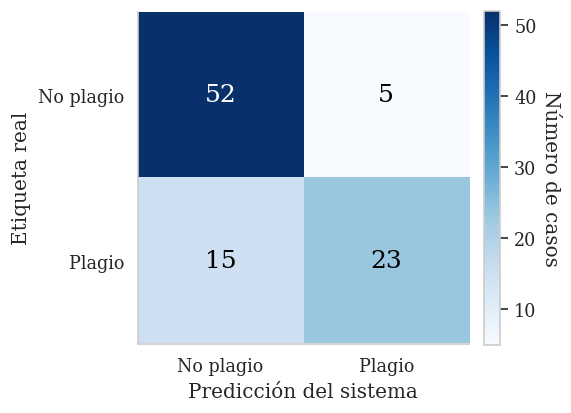

In [95]:
pred_final = prediccion_sistema_completo(df, MODELO_FINAL)
metricas_clough = metricas_binarias(df["etiqueta_real"], pred_final)

cm = np.array([
    [metricas_clough["TN"], metricas_clough["FP"]],
    [metricas_clough["FN"], metricas_clough["TP"]],
])

fig, ax = plt.subplots(figsize=(4.8, 4.3))

im = ax.imshow(cm, cmap="Blues")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(["No plagio", "Plagio"])
ax.set_yticklabels(["No plagio", "Plagio"])

ax.set_xlabel("Predicción del sistema")
ax.set_ylabel("Etiqueta real")

for i in range(2):
    for j in range(2):
        color_texto = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            fontsize=15,
            color=color_texto
        )

ax.grid(False)
cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.set_ylabel("Número de casos", rotation=270, labelpad=14)

finalizar_figura(f"clough_matriz_confusion_{MODELO_FINAL.replace(':', '_')}")

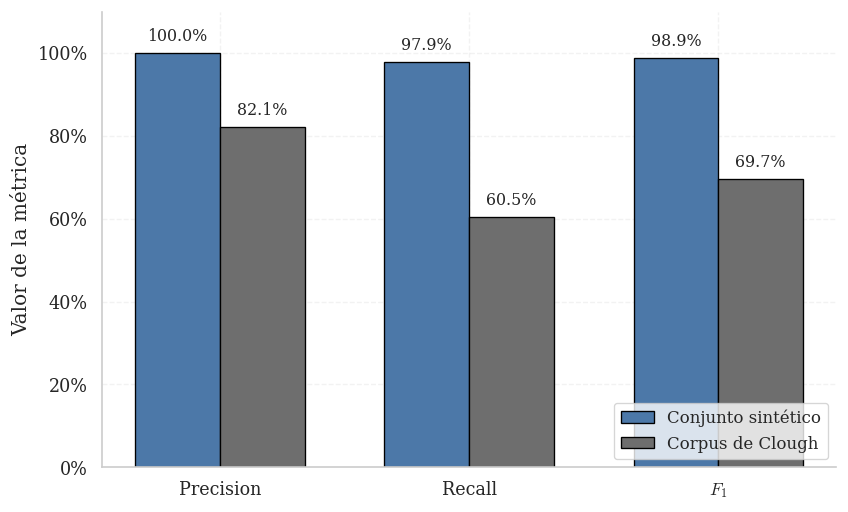

In [96]:
metricas_sintetico = {
    "Precision": 1.000,
    "Recall": 0.979,
    "F1": 0.989,
}

metricas_comparacion = ["Precision", "Recall", "F1"]

valores_sintetico = [metricas_sintetico[m] * 100 for m in metricas_comparacion]
valores_clough = [metricas_clough[m] * 100 for m in metricas_comparacion]

x = np.arange(len(metricas_comparacion))
width = 0.34

fig, ax = plt.subplots(figsize=(7.2, 4.4))

bars1 = ax.bar(
    x - width / 2,
    valores_sintetico,
    width,
    label="Conjunto sintético",
    color=COLOR_PLAGIO,
    edgecolor="black",
    linewidth=0.8
)

bars2 = ax.bar(
    x + width / 2,
    valores_clough,
    width,
    label="Corpus de Clough",
    color=COLOR_GRIS,
    edgecolor="black",
    linewidth=0.8
)

ax.set_xticks(x)
ax.set_xticklabels(["Precision", "Recall", r"$F_1$"])
ax.set_ylabel("Valor de la métrica")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_ylim(0, 110)
ax.legend(frameon=True, loc="lower right")

for bars in [bars1, bars2]:
    for bar in bars:
        altura = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            altura + 2,
            f"{altura:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9.5
        )

finalizar_figura(f"comparacion_sintetico_clough_{MODELO_FINAL.replace(':', '_')}")